# **Inteligencia Artificial con Aplicaciones en Economía I**

- 👩‍🏫 **Profesora:** Lina María Castro
- 🎓 **Universidad:** Universidad Externado de Colombia - Facultad de Economía

**Proyecto:** Brechas de desempeño en las pruebas Saber 11 (2020-2) entre zonas rurales y urbanas de Colombia: identificación de factores explicativos mediante aprendizaje automático

**Integrantes:** Juan Manuel Vellaizan · María Paula Orozco · Valery Nayuni Ccaulla · Nicolás Orduña

# **Modelos, evaluación e interpretación económica**

Este notebook responde la pregunta central del proyecto: **¿qué factores, más allá de la ubicación, explican la brecha rural-urbana en Saber 11 y cuánto aporta cada uno?**

## **Contenido del notebook**

**Parte A. Preparación de los datos:** partición por sede, selección de predictores y pipeline de preprocesamiento.

**Parte B. Modelo principal:** regresión del puntaje global mediante los modelos Lineal, Ridge, Lasso, Random Forest y Gradient Boosting.

**Parte C. Modelo complementario:** clasificación del riesgo de bajo desempeño, utilizando un umbral elegido sin emplear los datos de prueba.

**Parte D. Aporte de las variables incorporadas:** comparación de los resultados con y sin las variables adicionales.

**Parte E. Interpretación:** análisis de coeficientes, Oaxaca-Blinder, Shapley, importancia de variables, dependencia parcial, escenarios y focalización.

**Parte F. Tipología de sedes rurales oficiales:** aplicación de K-means como método de aprendizaje no supervisado.

## **Cambios frente a la versión anterior**

Se revisaron las 81 columnas de la base de datos (Notebook 1, sección 6) y se incorporaron 13 variables construidas a partir de 15 columnas que anteriormente no se utilizaban. Estas incluyen la ocupación de la madre y del padre, alimentación del hogar, situación económica frente al año anterior, focalización por Sisbén, migración, remuneración del trabajo, lectura por gusto, uso de internet, calendario, tipo de sede y dos indicadores de movilidad entre municipios.

El preprocesamiento ahora se realiza mediante un `ColumnTransformer` de scikit-learn. Además, el índice de bienes se construye con PCA sobre variables estandarizadas y se agregan los modelos Ridge, Lasso y Gradient Boosting de regresión.

##**Tiempo de ejecución**
 entre 25 y 35 minutos, debido al entrenamiento de varios modelos con validación cruzada sobre aproximadamente 450.000 estudiantes.

## 1. Importar librerías

In [ ]:
import os
from itertools import combinations
from math import factorial

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import warnings
warnings.filterwarnings("ignore")

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.model_selection import (GroupShuffleSplit, GroupKFold, GridSearchCV, cross_validate,
                                     cross_val_predict)
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor, HistGradientBoostingClassifier
from sklearn.metrics import (r2_score, mean_squared_error, mean_absolute_error, precision_score, recall_score,
                             f1_score, balanced_accuracy_score, roc_auc_score, average_precision_score,
                             confusion_matrix, roc_curve, precision_recall_curve, silhouette_score)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

SEMILLA = 42   # semilla fija para que los resultados sean reproducibles

In [ ]:
RUTA_TABLAS = os.path.join("..", "results", "tablas")
RUTA_FIGURAS = os.path.join("..", "results", "figuras")

COLOR = {"URBANO": "#2a78d6", "RURAL": "#eb6834"}
plt.rcParams.update({
    "figure.dpi": 100, "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "axes.axisbelow": True,
})


def guardar_figura(nombre):
    """Guarda la figura actual en results/figuras con buena resolución y la muestra."""
    plt.savefig(os.path.join(RUTA_FIGURAS, nombre), dpi=200, bbox_inches="tight")
    plt.show()


def guardar_tabla(tabla, nombre, index=False):
    """Guarda una tabla en results/tablas en formato CSV compatible con Excel."""
    tabla.to_csv(os.path.join(RUTA_TABLAS, nombre), index=index, encoding="utf-8-sig")

---
# PARTE A. Preparación de los datos para los modelos

## 2. Muestra de modelamiento

Se usan los estudiantes de jornadas regulares que respondieron el cuestionario socioeconómico. Quienes no lo respondieron (9.212) no se pueden caracterizar, pero sí se incluyeron en el análisis descriptivo del notebook 1 (parte B).

In [ ]:
df = pd.read_csv(os.path.join("..", "data", "processed", "base_analitica.csv.gz"),
                 dtype={"sede": str, "cod_depto": str, "cod_mcpio": str, "id_estudiante": str,
                        "establecimiento": str})
df = df[df["sin_cuestionario"] == 0].reset_index(drop=True)
print(f"Muestra de modelamiento: {len(df):,} estudiantes en {df['sede'].nunique():,} sedes")

Muestra de modelamiento: 449,695 estudiantes en 10,413 sedes


## 3. División en entrenamiento y prueba por sede

Si se dividiera al azar por estudiante, compañeros de un mismo colegio quedarían a ambos lados y el modelo «reconocería» el colegio. El error en prueba quedaría subestimado.

Por eso se usa `GroupShuffleSplit`: el 80 % de las sedes queda para entrenamiento y el 20 % para prueba. Así la prueba mide qué tan bien funciona el modelo con colegios que nunca vio.

In [ ]:
separador = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEMILLA)
indices_train, indices_test = next(separador.split(df, groups=df["sede"]))

train = df.loc[indices_train].reset_index(drop=True)
test = df.loc[indices_test].reset_index(drop=True)

sedes_compartidas = set(train["sede"]) & set(test["sede"])
print("Sedes que aparecen en ambos conjuntos:", len(sedes_compartidas))

resumen_particion = pd.concat([train.assign(conjunto="entrenamiento"), test.assign(conjunto="prueba")]) \
    .groupby(["conjunto", "zona"]).agg(estudiantes=("id_estudiante", "size"), sedes=("sede", "nunique"),
                                       puntaje_medio=("punt_global", "mean"))
guardar_tabla(resumen_particion, "03_particion_train_test.csv", index=True)
resumen_particion

Sedes que aparecen en ambos conjuntos: 0


estudiantes  sedes  puntaje_medio
conjunto      zona                                     
entrenamiento RURAL         60624   3077        228.409
              URBANO       296857   5253        256.836
prueba        RURAL         16197    770        229.621
              URBANO        76017   1313        257.198

## 4. Variables predictoras y grupos de factores

Cada variable se clasifica según cómo entra al modelo y se asigna a un grupo de factores. Los grupos se utilizan en la parte E para medir cuánto aporta cada tipo de factor a la brecha. Las variables marcadas con ★ se incorporan en esta versión.

### Grupos de factores y variables

**1. Ruralidad (efecto residual):**
- Zona rural.

**2. Colegio: tipo, jornada y sede:**
- Naturaleza.
- Jornada.
- Carácter.
- Género del colegio.
- Bilingüe.
- Calendario ★.
- Sede secundaria ★.

**3. Colegio: NSE de los pares:**
- NSE del establecimiento.

**4. Hogar: nivel socioeconómico:**
- Estrato.
- Libros.
- Índice de bienes (PCA).
- Hacinamiento.
- Personas en el hogar.
- Focalización por Sisbén ★.

**5. Hogar: educación y ocupación de los padres:**
- Educación de la madre y del padre.
- Ocupación de la madre ★ y del padre ★.

**6. Hogar: conectividad:**
- Internet.
- Computador.
- Uso diario de internet ★.

**7. Hogar: alimentación y situación económica:**
- Índice de alimentación ★.
- Situación económica frente al año anterior ★.

**8. Estudiante: características:**
- Género.
- Etnia.
- Edad.
- Migrante venezolano ★.

**9. Estudiante: trabajo y hábitos:**
- Horas de trabajo.
- Remuneración ★.
- Lectura diaria por gusto ★.

**10. Territorio: pobreza y movilidad:**
- IPM DANE del departamento y zona.
- Vive en otro municipio ★.
- Presenta el examen en otro municipio ★.

### **Variables de la base que NO entran como predictoras**

El detalle de las 81 columnas de la base de datos se encuentra en el archivo `01_inventario_variables.csv`.

Las siguientes variables no se incorporan directamente como predictoras en los modelos por razones metodológicas:

- **Puntajes, percentiles y niveles de desempeño por área:** forman parte del resultado que se busca explicar. Utilizarlos como predictores generaría fuga de información.

- **INSE y NSE individual:** resumen el estrato, los bienes y la educación de los padres, variables que ya están incorporadas en el modelo. Incluirlos generaría multicolinealidad.

- **Generación E en su modalidad «Excelencia»:** se asigna según el puntaje, por lo que su inclusión produciría fuga de información. Por esta razón, solo se utiliza el indicador de focalización por Sisbén, que depende de la situación del hogar y no del resultado académico.

- **Extraedad, trabaja, conectividad completa, inseguridad alimentaria y educación máxima de los padres:** se construyen a partir de variables que ya están incorporadas en el modelo, como edad, horas de trabajo, internet y computador, alimentación y educación de cada padre. Por tanto, serían redundantes. Se utilizan en el análisis descriptivo y en la tipología de la parte F.

- **Nacionalidad y país de residencia:** se resumen en el indicador de migrante venezolano, que representa el 99 % de los estudiantes extranjeros.

In [ ]:
# Variables binarias (0/1) que entran sin transformar: variable -> grupo
binarias = {
    "rural": "Ruralidad (efecto residual)",
    "sede_secundaria": "Colegio: tipo, jornada y sede",
    "focalizado_sisben": "Hogar: nivel socioeconómico",
    "migrante": "Estudiante: características",
    "estudia_otro_mcpio": "Territorio: pobreza y movilidad",
    "presenta_otro_mcpio": "Territorio: pobreza y movilidad",
}
# Variables categóricas: (categoría de referencia, grupo). Se convierten en dummies sin la referencia.
categoricas = {
    "naturaleza": ("Oficial", "Colegio: tipo, jornada y sede"),
    "jornada": ("Mañana", "Colegio: tipo, jornada y sede"),
    "caracter": ("Académico", "Colegio: tipo, jornada y sede"),
    "genero_colegio": ("Mixto", "Colegio: tipo, jornada y sede"),
    "bilingue": ("No", "Colegio: tipo, jornada y sede"),
    "calendario": ("A", "Colegio: tipo, jornada y sede"),
    "nse_colegio": ("NSE 1", "Colegio: NSE de los pares"),
    "estrato": ("Estrato 1", "Hogar: nivel socioeconómico"),
    "libros": ("0-10", "Hogar: nivel socioeconómico"),
    "educ_madre": ("Primaria o menos", "Hogar: educación y ocupación de los padres"),
    "educ_padre": ("Primaria o menos", "Hogar: educación y ocupación de los padres"),
    "ocup_madre": ("Hogar o no trabaja", "Hogar: educación y ocupación de los padres"),
    "ocup_padre": ("Agricultor o jornalero", "Hogar: educación y ocupación de los padres"),
    "internet": ("No", "Hogar: conectividad"),
    "computador": ("No", "Hogar: conectividad"),
    "uso_internet": ("No navega", "Hogar: conectividad"),
    "situacion_economica": ("Igual", "Hogar: alimentación y situación económica"),
    "genero": ("F", "Estudiante: características"),
    "etnia": ("No", "Estudiante: características"),
    "trabajo_horas": ("No trabaja", "Estudiante: trabajo y hábitos"),
    "remuneracion": ("No remunerado o no trabaja", "Estudiante: trabajo y hábitos"),
    "lectura_diaria": ("No lee", "Estudiante: trabajo y hábitos"),
}
# Variables numéricas: grupo
numericas = {
    "hacinamiento": "Hogar: nivel socioeconómico",
    "personas_hogar": "Hogar: nivel socioeconómico",
    "indice_alimentacion": "Hogar: alimentación y situación económica",
    "edad": "Estudiante: características",
    "ipm_zona": "Territorio: pobreza y movilidad",
}
# Los seis bienes del hogar se resumen en un índice con PCA (sección 5)
bienes = ["tiene_tv", "tiene_lavadora", "tiene_horno", "tiene_automovil", "tiene_moto", "tiene_consola"]

grupo_variable = {**binarias, **{v: g for v, (_, g) in categoricas.items()}, **numericas,
                  "indice_bienes_pca": "Hogar: nivel socioeconómico"}
grupos = list(dict.fromkeys(grupo_variable.values()))   # en orden de aparición, sin repetir

# Variables incorporadas en esta versión (se usan en la parte D para medir su aporte)
variables_nuevas = ["sede_secundaria", "calendario", "focalizado_sisben", "ocup_madre", "ocup_padre",
                    "uso_internet", "indice_alimentacion", "situacion_economica", "migrante", "remuneracion",
                    "lectura_diaria", "estudia_otro_mcpio", "presenta_otro_mcpio"]
print(f"{len(grupo_variable)} variables en {len(grupos)} grupos; {len(variables_nuevas)} son nuevas")

34 variables en 10 grupos; 13 son nuevas


## 5. Pipeline de preprocesamiento

Todo el preprocesamiento se organiza mediante un `ColumnTransformer` de scikit-learn, que aplica a cada tipo de variable su propia transformación. El ajuste se realiza únicamente con los datos de entrenamiento (`fit`) y posteriormente se aplica de la misma manera a los datos de prueba (`transform`). Así, las medianas, los percentiles de recorte, las categorías y el PCA nunca utilizan información de los datos de prueba.

### **Transformaciones según el tipo de variable**

**1. Variables binarias:**

Se dejan sin modificación, ya que sus valores originales están representados en una escala de 0 a 1.

**2. Variables categóricas:**

Se utiliza `OneHotEncoder` con una categoría de referencia. Esto permite interpretar cada coeficiente frente a una categoría de referencia con un sentido económico. Por ejemplo, se puede comparar una madre con educación primaria frente a una categoría de educación diferente.

Las categorías que no aparecen durante el entrenamiento se manejan mediante el parámetro `handle_unknown="ignore"`.

**3. Variables numéricas:**

Se aplica un recorte de valores extremos y posteriormente se realiza la imputación con la mediana, junto con un indicador de valores faltantes.

La edad se recorta utilizando los percentiles 1 y 99, mientras que el hacinamiento se recorta en el percentil 99, con el propósito de evitar que unos pocos valores extremos dominen la regresión.

El indicador de valores faltantes permite que el modelo distinga entre los casos en los que existe información y aquellos en los que no se respondió.

**4. Bienes del hogar:**

Se realiza una imputación, estandarización y posteriormente un Análisis de Componentes Principales (PCA) de un solo componente.

Este procedimiento resume seis bienes del hogar en un único índice de riqueza. La estandarización se realiza antes del PCA para evitar que algún bien tenga mayor influencia únicamente por su escala o varianza.

### **Estandarización adicional en los modelos**

Para los modelos de regresión lineal, Ridge, Lasso y regresión logística, se incorpora adicionalmente un `StandardScaler` dentro de cada modelo. Esto permite que la penalización trate de manera equilibrada a todas las variables.

Los modelos basados en árboles no necesitan esta estandarización adicional.

In [ ]:
class Recortador(BaseEstimator, TransformerMixin):
    """
    Recorta (winsoriza) columnas numéricas entre percentiles calculados en el entrenamiento.

    Parámetros:
        inferior (dict): columna -> percentil inferior (entre 0 y 1).
        superior (dict): columna -> percentil superior (entre 0 y 1).
    """
    def __init__(self, inferior=None, superior=None):
        self.inferior = inferior
        self.superior = superior

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        inferior, superior = self.inferior or {}, self.superior or {}
        self.limites_ = {c: (X[c].quantile(inferior[c]) if c in inferior else -np.inf,
                             X[c].quantile(superior[c]) if c in superior else np.inf) for c in X.columns}
        self.columnas_ = np.array(X.columns)
        return self

    def transform(self, X):
        X = pd.DataFrame(X).copy()
        for columna, (minimo, maximo) in self.limites_.items():
            X[columna] = X[columna].clip(minimo, maximo)
        return X

    def get_feature_names_out(self, input_features=None):
        return self.columnas_


class IndicePCA(BaseEstimator, TransformerMixin):
    """
    Índice de bienes del hogar: primer componente principal de los bienes, previamente estandarizados.
    Imputa con la moda, estandariza, aplica PCA y orienta el signo para que más bienes = índice mayor.
    Agrega un indicador de si faltaba alguno de los bienes.
    """
    def __init__(self, nombre="indice_bienes_pca"):
        self.nombre = nombre

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.imputador_ = SimpleImputer(strategy="most_frequent").fit(X)
        Z = self.imputador_.transform(X)
        self.escalador_ = StandardScaler().fit(Z)
        self.pca_ = PCA(n_components=1, random_state=SEMILLA).fit(self.escalador_.transform(Z))
        self.signo_ = 1.0 if self.pca_.components_[0].sum() >= 0 else -1.0
        self.cargas_ = pd.Series(self.pca_.components_[0] * self.signo_, index=X.columns)
        self.varianza_explicada_ = self.pca_.explained_variance_ratio_[0]
        return self

    def transform(self, X):
        X = pd.DataFrame(X)
        Z = self.escalador_.transform(self.imputador_.transform(X))
        return pd.DataFrame({self.nombre: self.pca_.transform(Z)[:, 0] * self.signo_,
                             "bienes_faltante": X.isna().any(axis=1).astype(float).values}, index=X.index)

    def get_feature_names_out(self, input_features=None):
        return np.array([self.nombre, "bienes_faltante"])


def nombre_dummy(variable, categoria):
    """Nombre de cada dummy: 'variable=categoría'."""
    return f"{variable}={categoria}"


preprocesador = ColumnTransformer([
    ("binarias", "passthrough", list(binarias)),
    ("categoricas", OneHotEncoder(drop=[referencia for referencia, _ in categoricas.values()],
                                  handle_unknown="ignore", sparse_output=False,
                                  feature_name_combiner=nombre_dummy), list(categoricas)),
    ("bienes", IndicePCA(), bienes),
    ("numericas", Pipeline([("recorte", Recortador(inferior={"edad": 0.01},
                                                    superior={"edad": 0.99, "hacinamiento": 0.99})),
                            ("imputacion", SimpleImputer(strategy="median", add_indicator=True))]),
     list(numericas)),
], verbose_feature_names_out=False).set_output(transform="pandas")
preprocesador

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('binarias', ...), ('categoricas', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features pe

In [ ]:
X_train = preprocesador.fit_transform(train).astype(float)   # se ajusta SOLO con el entrenamiento
X_test = preprocesador.transform(test).astype(float)          # la prueba solo se transforma

y_train = train["punt_global"].values
y_test = test["punt_global"].values
grupos_train = train["sede"].values


def variable_de_columna(columna):
    """Variable original de una columna de la matriz (une las dummies y los indicadores de faltante)."""
    if columna.startswith("missingindicator_"):
        return columna.replace("missingindicator_", "")
    if columna == "bienes_faltante":
        return "indice_bienes_pca"
    return columna.split("=")[0]


def grupo_de_columna(columna):
    """Grupo de factores al que pertenece una columna de la matriz."""
    return grupo_variable[variable_de_columna(columna)]


print("Matriz de entrenamiento:", X_train.shape, "| Matriz de prueba:", X_test.shape)
print("Columnas iguales en entrenamiento y prueba:", list(X_train.columns) == list(X_test.columns))
print("Valores faltantes después del preprocesamiento:", int(X_train.isna().sum().sum() + X_test.isna().sum().sum()))

Matriz de entrenamiento: (357481, 101) | Matriz de prueba: (92214, 101)
Columnas iguales en entrenamiento y prueba: True
Valores faltantes después del preprocesamiento: 0


In [ ]:
# Índice de bienes: cargas del primer componente y varianza que explica
pca_bienes = preprocesador.named_transformers_["bienes"]
print(f"El primer componente explica el {pca_bienes.varianza_explicada_ * 100:.1f} % de la varianza de los seis bienes")
cargas_pca = pca_bienes.cargas_.rename("carga").to_frame()
guardar_tabla(cargas_pca, "03_pca_indice_bienes_cargas.csv", index=True)
cargas_pca

El primer componente explica el 32.2 % de la varianza de los seis bienes


,carga
tiene_tv,0.416
tiene_lavadora,0.422
tiene_horno,0.490
tiene_automovil,0.451
tiene_moto,0.048
tiene_consola,0.451


El primer componente resume el 32 % de la variación de los seis bienes. Televisión, lavadora, horno, automóvil y consola pesan casi igual (cargas entre 0,42 y 0,49), mientras que la motocicleta casi no pesa (0,05): es común tanto en hogares de ingresos bajos como altos, sobre todo en lo rural, donde es un medio de transporte, así que no distingue riqueza. La suma simple de bienes que se usaba antes la contaba igual que un automóvil; el PCA corrige eso.

## 6. Multicolinealidad: factor de inflación de varianza (VIF)

El VIF mide cuánto se explica cada variable con las demás. Un VIF mayor que 10 indica multicolinealidad fuerte, y con ella los coeficientes individuales se vuelven poco confiables. El VIF de cada variable se obtiene de la diagonal de la inversa de la matriz de correlaciones.

In [ ]:
matriz_corr = np.corrcoef(X_train.values, rowvar=False)
vif = pd.DataFrame({"variable": X_train.columns, "VIF": np.diag(np.linalg.pinv(matriz_corr))})
vif = vif.sort_values("VIF", ascending=False).reset_index(drop=True)
guardar_tabla(vif, "03_vif_multicolinealidad.csv")
print("Variables con VIF > 10:", (vif["VIF"] > 10).sum())
vif.head(8)

Variables con VIF > 10: 0


,variable,VIF
0,nse_colegio=NSE 3,8.771
1,nse_colegio=NSE 2,6.915
2,uso_internet=1-3 h,5.445
3,uso_internet=Más de 3 h,5.387
4,uso_internet=30-60 min,4.358
5,missingindicator_personas_hogar,4.281
6,missingindicator_hacinamiento,3.501
7,nse_colegio=NSE 4,3.397


Ninguna variable supera 10. Los VIF más altos son los del NSE del colegio (8,8 y 6,9), por su relación con la zona y el IPM, y los del uso diario de internet (alrededor de 5,4), por su relación con tener internet en casa. Esto no impide estimar el modelo, pero indica que conviene interpretar grupos de variables y no cada coeficiente por separado (parte E).

---
# PARTE B. Modelo principal: regresión del puntaje global

## 7. Funciones de evaluación

- **R²:** proporción de la variación del puntaje que explica el modelo (0 = nada, 1 = todo).
- **RMSE:** error típico de predicción, en puntos. Penaliza más los errores grandes.
- **MAE:** error absoluto promedio, en puntos.

Cada modelo se evalúa de tres formas: en entrenamiento, con validación cruzada de 5 pliegues agrupada por sede (`GroupKFold`) y en prueba. Si el modelo va mucho mejor en entrenamiento que en prueba, hay sobreajuste.

In [ ]:
def metricas_regresion(y_real, y_predicho):
    """Retorna un diccionario con R², RMSE y MAE."""
    return {"R2": r2_score(y_real, y_predicho),
            "RMSE": np.sqrt(mean_squared_error(y_real, y_predicho)),
            "MAE": mean_absolute_error(y_real, y_predicho)}


def validacion_cruzada_regresion(modelo, X, y, grupos, pliegues=5):
    """Validación cruzada agrupada por sede. Retorna el promedio y la desviación de cada métrica."""
    cv = cross_validate(modelo, X, y, groups=grupos, cv=GroupKFold(n_splits=pliegues),
                        scoring={"r2": "r2", "rmse": "neg_root_mean_squared_error",
                                 "mae": "neg_mean_absolute_error"})
    return {"CV_R2": cv["test_r2"].mean(), "CV_R2_sd": cv["test_r2"].std(),
            "CV_RMSE": -cv["test_rmse"].mean(), "CV_MAE": -cv["test_mae"].mean()}

## 8. Ajuste de hiperparámetros

Todos los ajustes usan validación cruzada agrupada por sede y se hacen sobre el 35 % de las sedes de entrenamiento, para que no tomen demasiado tiempo. La prueba no se usa en ningún momento.

- **Ridge y Lasso** (`GridSearchCV`): penalizan el tamaño de los coeficientes. Ridge los encoge todos; Lasso puede llevar algunos exactamente a cero, lo que sirve para ver qué variables sobran. Se busca el mejor `alpha`.
- **Random Forest:** `max_depth` (profundidad de cada árbol) y `min_samples_leaf` (estudiantes mínimos por hoja). Quedan fijos 120 árboles, cada uno entrenado con el 30 % de los datos y con un tercio de las variables en cada división.
- **Gradient Boosting** (`HistGradientBoostingRegressor`, de la misma familia que XGBoost): tasa de aprendizaje y número de hojas, con parada temprana.

In [ ]:
generador = np.random.default_rng(SEMILLA)
sedes_train = np.unique(grupos_train)
sedes_muestra = generador.choice(sedes_train, size=int(len(sedes_train) * 0.35), replace=False)
en_muestra = np.isin(grupos_train, sedes_muestra)
X_ajuste, y_ajuste, g_ajuste = X_train[en_muestra], y_train[en_muestra], grupos_train[en_muestra]
print(f"Muestra de ajuste: {en_muestra.sum():,} estudiantes de {len(sedes_muestra):,} sedes")

ajustes_lineales = {}
for nombre, modelo, rejilla in [
        ("Ridge", Ridge(), {"modelo__alpha": [1, 10, 100, 1000, 10000]}),
        ("Lasso", Lasso(max_iter=5000), {"modelo__alpha": [0.01, 0.05, 0.1, 0.5, 1.0]})]:
    busqueda = GridSearchCV(Pipeline([("escala", StandardScaler()), ("modelo", modelo)]), rejilla,
                            scoring="neg_root_mean_squared_error", cv=GroupKFold(n_splits=5), n_jobs=-1)
    busqueda.fit(X_ajuste, y_ajuste, groups=g_ajuste)
    ajustes_lineales[nombre] = busqueda.best_params_["modelo__alpha"]
    resultados = pd.DataFrame(busqueda.cv_results_)[["param_modelo__alpha", "mean_test_score"]]
    print(f"{nombre}: RMSE por alpha =",
          {a: round(-s, 3) for a, s in zip(resultados["param_modelo__alpha"], resultados["mean_test_score"])},
          "| mejor alpha:", ajustes_lineales[nombre])

Muestra de ajuste: 128,326 estudiantes de 2,915 sedes
Ridge: RMSE por alpha = {1: 37.724, 10: 37.724, 100: 37.724, 1000: 37.723, 10000: 37.798} | mejor alpha: 1000
Lasso: RMSE por alpha = {0.01: 37.724, 0.05: 37.73, 0.1: 37.748, 0.5: 37.994, 1.0: 38.388} | mejor alpha: 0.01


In [ ]:
rf_base = {"n_estimators": 120, "max_samples": 0.3, "max_features": 0.33, "n_jobs": -1, "random_state": SEMILLA}
combinaciones_rf = [{"max_depth": 12, "min_samples_leaf": 20}, {"max_depth": 12, "min_samples_leaf": 100},
                    {"max_depth": 20, "min_samples_leaf": 20}, {"max_depth": 20, "min_samples_leaf": 100}]
hgbr_base = {"max_iter": 600, "early_stopping": True, "validation_fraction": 0.1, "n_iter_no_change": 20,
             "min_samples_leaf": 100, "l2_regularization": 1.0, "random_state": SEMILLA}
combinaciones_hgbr = [{"learning_rate": 0.05, "max_leaf_nodes": 31}, {"learning_rate": 0.05, "max_leaf_nodes": 63},
                      {"learning_rate": 0.1, "max_leaf_nodes": 31}, {"learning_rate": 0.1, "max_leaf_nodes": 63}]

filas = []
for nombre, clase, base, combinaciones in [("Random Forest", RandomForestRegressor, rf_base, combinaciones_rf),
                                           ("Gradient Boosting", HistGradientBoostingRegressor, hgbr_base,
                                            combinaciones_hgbr)]:
    for combinacion in combinaciones:
        resultado = validacion_cruzada_regresion(clase(**base, **combinacion), X_ajuste, y_ajuste, g_ajuste, pliegues=3)
        filas.append({"modelo": nombre, **combinacion, **resultado})
        print(f"{nombre} {combinacion}: RMSE = {resultado['CV_RMSE']:.2f} | R2 = {resultado['CV_R2']:.3f}")

ajuste_arboles = pd.DataFrame(filas).sort_values(["modelo", "CV_RMSE"])
guardar_tabla(ajuste_arboles, "03_ajuste_hiperparametros_regresion.csv")


def mejor_combinacion(modelo, parametros):
    """Combinación de hiperparámetros con menor RMSE en validación cruzada para un modelo."""
    fila = ajuste_arboles[ajuste_arboles["modelo"] == modelo].iloc[0]
    return {p: (float(fila[p]) if p == "learning_rate" else int(fila[p])) for p in parametros}


mejor_rf = mejor_combinacion("Random Forest", ["max_depth", "min_samples_leaf"])
mejor_hgbr = mejor_combinacion("Gradient Boosting", ["learning_rate", "max_leaf_nodes"])
print("Mejor Random Forest:", mejor_rf, "| Mejor Gradient Boosting:", mejor_hgbr)

Random Forest {'max_depth': 12, 'min_samples_leaf': 20}: RMSE = 38.57 | R2 = 0.353
Random Forest {'max_depth': 12, 'min_samples_leaf': 100}: RMSE = 39.10 | R2 = 0.335
Random Forest {'max_depth': 20, 'min_samples_leaf': 20}: RMSE = 38.33 | R2 = 0.361
Random Forest {'max_depth': 20, 'min_samples_leaf': 100}: RMSE = 39.07 | R2 = 0.336
Gradient Boosting {'learning_rate': 0.05, 'max_leaf_nodes': 31}: RMSE = 36.70 | R2 = 0.414
Gradient Boosting {'learning_rate': 0.05, 'max_leaf_nodes': 63}: RMSE = 36.73 | R2 = 0.413
Gradient Boosting {'learning_rate': 0.1, 'max_leaf_nodes': 31}: RMSE = 36.75 | R2 = 0.412
Gradient Boosting {'learning_rate': 0.1, 'max_leaf_nodes': 63}: RMSE = 36.82 | R2 = 0.410
Mejor Random Forest: {'max_depth': 20, 'min_samples_leaf': 20} | Mejor Gradient Boosting: {'learning_rate': 0.05, 'max_leaf_nodes': 31}


## 9. Entrenamiento y evaluación de los modelos de regresión

Para evaluar el desempeño de los modelos, se utilizan diferentes alternativas de regresión. Cada una cumple una función específica dentro del análisis.

**1. Línea base: media**

Predice el mismo promedio para todos los estudiantes. Representa el nivel mínimo de referencia que cualquier modelo debe superar.

**2. Línea base: solo zona**

Realiza una regresión utilizando únicamente la variable rural. Permite medir cuánto explica la ubicación por sí sola y representa la brecha rural-urbana sin incorporar otros factores.

**3. Regresión lineal**

Es un modelo interpretable cuyos coeficientes se utilizan en la descomposición de Oaxaca-Blinder para analizar y explicar los componentes de la brecha rural-urbana.

**4. Ridge y Lasso**

Son modelos de regresión lineal penalizada. Permiten evaluar si la regularización mejora la capacidad de predicción al trabajar con un mayor número de variables.

**5. Random Forest**

Permite identificar relaciones no lineales e interacciones entre las diferentes variables, capturando patrones que una regresión lineal podría no identificar.

**6. Gradient Boosting**

Utiliza una secuencia de árboles de decisión que corrigen progresivamente los errores de los modelos anteriores. Pertenece a la familia de algoritmos de aprendizaje automático como XGBoost.

In [ ]:
def escalado(modelo):
    """Pipeline que estandariza las variables antes de un modelo lineal."""
    return Pipeline([("escala", StandardScaler()), ("modelo", modelo)])


todas = list(X_train.columns)
modelos_regresion = {
    "Línea base: media": (DummyRegressor(strategy="mean"), todas),
    "Línea base: solo zona": (LinearRegression(), ["rural"]),
    "Regresión lineal": (escalado(LinearRegression()), todas),
    "Ridge": (escalado(Ridge(alpha=ajustes_lineales["Ridge"])), todas),
    "Lasso": (escalado(Lasso(alpha=ajustes_lineales["Lasso"], max_iter=5000)), todas),
    "Random Forest": (RandomForestRegressor(**rf_base, **mejor_rf), todas),
    "Gradient Boosting": (HistGradientBoostingRegressor(**hgbr_base, **mejor_hgbr), todas),
}

filas = []
predicciones_test = {}
modelos_entrenados = {}
for nombre, (modelo, columnas) in modelos_regresion.items():
    cv = validacion_cruzada_regresion(modelo, X_train[columnas], y_train, grupos_train)
    modelo.fit(X_train[columnas], y_train)
    pred_train = modelo.predict(X_train[columnas])
    pred_test = modelo.predict(X_test[columnas])
    predicciones_test[nombre] = pred_test
    modelos_entrenados[nombre] = modelo

    fila = {"modelo": nombre}
    for metrica, valor in metricas_regresion(y_train, pred_train).items():
        fila[f"train_{metrica}"] = valor
    fila.update(cv)
    for metrica, valor in metricas_regresion(y_test, pred_test).items():
        fila[f"test_{metrica}"] = valor
    # Sesgo por zona: error y residuo promedio en cada zona
    for zona in ["URBANO", "RURAL"]:
        es_zona = test["zona"].values == zona
        fila[f"test_RMSE_{zona.lower()}"] = np.sqrt(mean_squared_error(y_test[es_zona], pred_test[es_zona]))
        fila[f"residuo_medio_{zona.lower()}"] = np.mean(y_test[es_zona] - pred_test[es_zona])
    fila["brecha_observada_test"] = y_test[test["rural"] == 0].mean() - y_test[test["rural"] == 1].mean()
    fila["brecha_predicha_test"] = pred_test[test["rural"] == 0].mean() - pred_test[test["rural"] == 1].mean()
    filas.append(fila)
    print(f"{nombre}: R2 CV = {fila['CV_R2']:.3f} | R2 prueba = {fila['test_R2']:.3f} | RMSE prueba = {fila['test_RMSE']:.2f}")

metricas_reg = pd.DataFrame(filas)
metricas_reg["sobreajuste_R2_train_menos_test"] = metricas_reg["train_R2"] - metricas_reg["test_R2"]
guardar_tabla(metricas_reg, "03_metricas_regresion.csv")
metricas_reg[["modelo", "train_R2", "CV_R2", "CV_R2_sd", "CV_RMSE", "test_R2", "test_RMSE", "test_MAE",
              "sobreajuste_R2_train_menos_test"]]

Línea base: media: R2 CV = -0.001 | R2 prueba = -0.000 | RMSE prueba = 48.64
Línea base: solo zona: R2 CV = 0.049 | R2 prueba = 0.046 | RMSE prueba = 47.50
Regresión lineal: R2 CV = 0.376 | R2 prueba = 0.393 | RMSE prueba = 37.89
Ridge: R2 CV = 0.376 | R2 prueba = 0.393 | RMSE prueba = 37.90
Lasso: R2 CV = 0.376 | R2 prueba = 0.393 | RMSE prueba = 37.90
Random Forest: R2 CV = 0.370 | R2 prueba = 0.387 | RMSE prueba = 38.09
Gradient Boosting: R2 CV = 0.422 | R2 prueba = 0.434 | RMSE prueba = 36.58


,modelo,train_R2,CV_R2,CV_R2_sd,CV_RMSE,test_R2,test_RMSE,test_MAE,sobreajuste_R2_train_menos_test
0,Línea base: media,0.000,-0.001,0.001,47.904,-0.000,48.643,39.820,0.000
1,Línea base: solo zona,0.050,0.049,0.004,46.702,0.046,47.500,38.693,0.003
2,Regresión lineal,0.378,0.376,0.011,37.809,0.393,37.894,30.372,-0.015
3,Ridge,0.378,0.376,0.011,37.809,0.393,37.896,30.375,-0.015
4,Lasso,0.378,0.376,0.011,37.809,0.393,37.896,30.376,-0.015
5,Random Forest,0.411,0.370,0.012,38.015,0.387,38.092,30.608,0.024
6,Gradient Boosting,0.448,0.422,0.009,36.408,0.434,36.583,29.219,0.014


In [ ]:
# Sesgo por zona: ¿el modelo se equivoca sistemáticamente más con los rurales?
metricas_reg[["modelo", "test_RMSE_urbano", "test_RMSE_rural", "residuo_medio_urbano", "residuo_medio_rural",
              "brecha_observada_test", "brecha_predicha_test"]]

,modelo,test_RMSE_urbano,test_RMSE_rural,residuo_medio_urbano,residuo_medio_rural,brecha_observada_test,brecha_predicha_test
0,Línea base: media,48.261,50.397,5.183,-22.394,27.577,-0.000
1,Línea base: solo zona,47.983,45.165,0.363,1.212,27.577,28.426
2,Regresión lineal,38.452,35.156,0.045,-1.112,27.577,26.420
3,Ridge,38.454,35.155,0.044,-1.103,27.577,26.430
4,Lasso,38.454,35.158,0.040,-1.087,27.577,26.451
5,Random Forest,38.733,34.926,-0.049,-0.976,27.577,26.650
6,Gradient Boosting,37.227,33.399,0.383,-1.086,27.577,26.108


In [ ]:
# El mejor modelo no lineal se elige por el RMSE de validación cruzada (no por la prueba)
no_lineales = metricas_reg[metricas_reg["modelo"].isin(["Random Forest", "Gradient Boosting"])]
nombre_no_lineal = no_lineales.sort_values("CV_RMSE")["modelo"].iloc[0]
modelo_no_lineal = modelos_entrenados[nombre_no_lineal]
modelo_lineal = modelos_entrenados["Regresión lineal"]
print("Modelo no lineal que se usa en la interpretación:", nombre_no_lineal)

# Variables que Lasso lleva a cero (no aportan una vez se controla por las demás)
coef_lasso = pd.Series(modelos_entrenados["Lasso"].named_steps["modelo"].coef_, index=todas)
print(f"Lasso deja {(coef_lasso != 0).sum()} de {len(coef_lasso)} columnas. Columnas en cero:")
print(sorted(coef_lasso[coef_lasso == 0].index))

Modelo no lineal que se usa en la interpretación: Gradient Boosting
Lasso deja 101 de 101 columnas. Columnas en cero:
[]


**Gráfica 7. Comparación de los modelos de regresión.** Compara el R² en validación cruzada (con su desviación entre pliegues) y en prueba. Si las dos barras de un modelo son parecidas, el modelo generaliza bien.

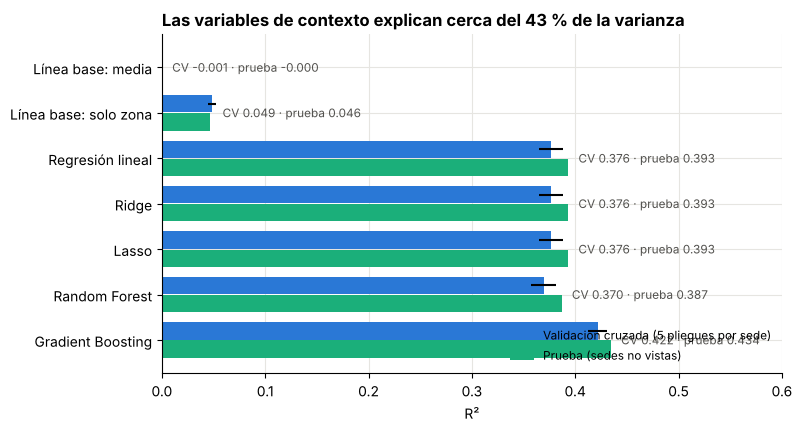

In [ ]:
plt.figure(figsize=(8, 4.4))
y = np.arange(len(metricas_reg))
plt.barh(y - 0.2, metricas_reg["CV_R2"], height=0.38, color="#2a78d6", xerr=metricas_reg["CV_R2_sd"],
         label="Validación cruzada (5 pliegues por sede)")
plt.barh(y + 0.2, metricas_reg["test_R2"], height=0.38, color="#1baf7a", label="Prueba (sedes no vistas)")
for i in range(len(metricas_reg)):
    plt.text(max(metricas_reg["CV_R2"][i], metricas_reg["test_R2"][i]) + 0.01, i,
             f"CV {metricas_reg['CV_R2'][i]:.3f} · prueba {metricas_reg['test_R2'][i]:.3f}",
             va="center", fontsize=8.5, color="#52514e")
plt.yticks(y, metricas_reg["modelo"])
plt.gca().invert_yaxis()
plt.xlim(0, 0.6)
plt.xlabel("R²")
plt.title(f"Las variables de contexto explican cerca del {metricas_reg['test_R2'].max() * 100:.0f} % de la varianza")
plt.legend(loc="lower right", frameon=False, fontsize=8.5)
guardar_figura("G7_comparacion_modelos_regresion.png")

**Lectura.**

- **La zona sola explica poco.** Explica menos del 5 % de la variación individual del puntaje (R² = 0,046). Las variables de contexto explican entre el 39 % y el 43 %; el resto depende de factores que la base no mide, como la habilidad, la motivación o la calidad docente.
- **El Gradient Boosting es el mejor modelo.** Obtiene R² = 0,434 y RMSE = 36,6 puntos en sedes que no vio, frente a 0,393 y 37,9 de la regresión lineal. Con las variables nuevas, las relaciones no lineales y las interacciones pesan más que antes. El Random Forest (0,387) queda por debajo de la regresión lineal: con árboles entrenados sobre el 30 % de los datos aprovecha menos la información que el *boosting*.
- **Ridge y Lasso no mejoran a la regresión lineal.** Con 357.000 estudiantes y 101 columnas no hay sobreajuste que corregir: el mejor `alpha` de Lasso no lleva ningún coeficiente a cero, es decir, **ninguna de las 101 columnas sobra**.
- **Sobreajuste.** Es pequeño: el R² del Gradient Boosting baja de 0,448 en entrenamiento a 0,434 en prueba. En la regresión lineal la prueba queda incluso un poco por encima (las sedes de prueba resultaron algo más fáciles de predecir; la validación cruzada, 0,376, es la referencia más prudente).
- **Sesgo por zona.** No hay un sesgo relevante: el residuo medio rural es de −1,1 puntos, y la brecha que predice el Gradient Boosting (26,1) es cercana a la observada en la prueba (27,6).

---
# PARTE C. Modelo complementario: clasificación del riesgo de bajo desempeño

## 10. Variable objetivo y desbalance de clases

Un estudiante tiene bajo desempeño si su puntaje global está por debajo del **percentil 25** del conjunto de entrenamiento. Este modelo responde una pregunta de política: ¿a quién y dónde focalizar?

Como solo el 25 % de los estudiantes está en la clase positiva, no se usa la exactitud (*accuracy*): un modelo que dijera «nadie tiene bajo desempeño» acertaría el 75 % de las veces. Se usan métricas que no se dejan engañar por el desbalance:

- **ROC-AUC y PR-AUC:** miden qué tan bien ordena el modelo a los estudiantes por riesgo, sin depender de un umbral. El PR-AUC es más exigente con la clase minoritaria; su referencia es la proporción de positivos (0,25).
- **Precisión, recall y F1** en el umbral elegido, y exactitud balanceada (promedio del recall de cada clase).

Los modelos usan `class_weight="balanced"`, que da más peso a la clase minoritaria.

In [ ]:
umbral_bajo = np.percentile(y_train, 25)   # percentil 25 del entrenamiento
yb_train = (y_train < umbral_bajo).astype(int)
yb_test = (y_test < umbral_bajo).astype(int)
print(f"Umbral de bajo desempeño: {umbral_bajo:.0f} puntos")
print(f"Proporción con bajo desempeño: entrenamiento {yb_train.mean():.3f} | prueba {yb_test.mean():.3f}")
pd.Series(yb_test).groupby(test["zona"]).mean().rename("proporción con bajo desempeño (prueba)")

Umbral de bajo desempeño: 216 puntos
Proporción con bajo desempeño: entrenamiento 0.250 | prueba 0.252


zona
RURAL    0.435
URBANO   0.214
Name: proporción con bajo desempeño (prueba), dtype: float64

## 11. Ajuste de hiperparámetros de los clasificadores

- **Regresión logística** (con estandarización): se busca la regularización `C` con `GridSearchCV`.
- **Gradient Boosting** (`HistGradientBoostingClassifier`): tasa de aprendizaje y número de hojas.

Ambos se eligen por el PR-AUC en validación cruzada agrupada por sede, sobre la misma muestra del 35 % de las sedes de entrenamiento.

In [ ]:
yb_ajuste = yb_train[en_muestra]

busqueda_logit = GridSearchCV(
    Pipeline([("escala", StandardScaler()),
              ("modelo", LogisticRegression(class_weight="balanced", max_iter=3000))]),
    {"modelo__C": [0.001, 0.01, 0.1, 1.0]}, scoring="average_precision", cv=GroupKFold(n_splits=5), n_jobs=-1)
busqueda_logit.fit(X_ajuste, yb_ajuste, groups=g_ajuste)
mejor_C = busqueda_logit.best_params_["modelo__C"]
print("Logística: PR-AUC por C =", dict(zip(busqueda_logit.cv_results_["param_modelo__C"],
                                           busqueda_logit.cv_results_["mean_test_score"].round(4))),
      "| mejor C:", mejor_C)

hgb_base = {"max_iter": 500, "early_stopping": True, "validation_fraction": 0.1, "n_iter_no_change": 20,
            "min_samples_leaf": 100, "l2_regularization": 1.0, "class_weight": "balanced",
            "random_state": SEMILLA}
filas = []
for combinacion in combinaciones_hgbr:
    cv = cross_validate(HistGradientBoostingClassifier(**hgb_base, **combinacion), X_ajuste, yb_ajuste,
                        groups=g_ajuste, cv=GroupKFold(3), scoring={"pr_auc": "average_precision", "roc_auc": "roc_auc"})
    filas.append({**combinacion, "CV_PR_AUC": cv["test_pr_auc"].mean(), "CV_ROC_AUC": cv["test_roc_auc"].mean()})
    print(f"Gradient Boosting {combinacion}: PR-AUC = {filas[-1]['CV_PR_AUC']:.4f}")

ajuste_hgb = pd.DataFrame(filas).sort_values("CV_PR_AUC", ascending=False)
guardar_tabla(ajuste_hgb, "03_hgb_ajuste_hiperparametros.csv")
mejor_hgb = {"learning_rate": float(ajuste_hgb.iloc[0]["learning_rate"]),
             "max_leaf_nodes": int(ajuste_hgb.iloc[0]["max_leaf_nodes"])}
print("Mejor Gradient Boosting:", mejor_hgb)

Logística: PR-AUC por C = {np.float64(0.001): np.float64(0.5717), np.float64(0.01): np.float64(0.5728), np.float64(0.1): np.float64(0.5729), np.float64(1.0): np.float64(0.5729)} | mejor C: 1.0
Gradient Boosting {'learning_rate': 0.05, 'max_leaf_nodes': 31}: PR-AUC = 0.5921
Gradient Boosting {'learning_rate': 0.05, 'max_leaf_nodes': 63}: PR-AUC = 0.5894
Gradient Boosting {'learning_rate': 0.1, 'max_leaf_nodes': 31}: PR-AUC = 0.5913
Gradient Boosting {'learning_rate': 0.1, 'max_leaf_nodes': 63}: PR-AUC = 0.5882
Mejor Gradient Boosting: {'learning_rate': 0.05, 'max_leaf_nodes': 31}


## 12. Elección del umbral sin usar la prueba

Con `class_weight="balanced"` las probabilidades quedan infladas y el umbral de 0,5 marca como riesgo a demasiados estudiantes. El umbral se elige con predicciones fuera de muestra del entrenamiento (`cross_val_predict` con 5 pliegues agrupados por sede): cada probabilidad la calcula un modelo que no vio la sede del estudiante. Se elige el umbral que maximiza el F1 y, como alternativa para política, el umbral que garantiza un recall de al menos 0,80 (encontrar a 8 de cada 10 estudiantes en riesgo). La prueba solo se usa al final, con el umbral ya fijo.

In [ ]:
modelos_clasificacion = {
    "Regresión logística": Pipeline([("escala", StandardScaler()),
                                     ("modelo", LogisticRegression(C=mejor_C, class_weight="balanced", max_iter=3000))]),
    "Gradient Boosting (HGB)": HistGradientBoostingClassifier(**hgb_base, **mejor_hgb),
}

umbrales = {}
probabilidades_oof_train = {}
for nombre, modelo in modelos_clasificacion.items():
    prob_oof = cross_val_predict(modelo, X_train, yb_train, groups=grupos_train, cv=GroupKFold(5),
                                 method="predict_proba", n_jobs=1)[:, 1]
    probabilidades_oof_train[nombre] = prob_oof
    precision, recall, cortes = precision_recall_curve(yb_train, prob_oof)
    f1 = 2 * precision[:-1] * recall[:-1] / np.maximum(precision[:-1] + recall[:-1], 1e-12)
    umbrales[nombre] = {"umbral_f1": cortes[np.argmax(f1)],
                        "umbral_recall_80": cortes[np.where(recall[:-1] >= 0.80)[0].max()]}
    print(f"{nombre}: ROC-AUC OOF = {roc_auc_score(yb_train, prob_oof):.3f} | PR-AUC OOF = "
          f"{average_precision_score(yb_train, prob_oof):.3f} | umbral F1 = {umbrales[nombre]['umbral_f1']:.3f} | "
          f"umbral recall 0,80 = {umbrales[nombre]['umbral_recall_80']:.3f}")

Regresión logística: ROC-AUC OOF = 0.796 | PR-AUC OOF = 0.575 | umbral F1 = 0.531 | umbral recall 0,80 = 0.432
Gradient Boosting (HGB): ROC-AUC OOF = 0.813 | PR-AUC OOF = 0.606 | umbral F1 = 0.544 | umbral recall 0,80 = 0.445


## 13. Evaluación de los clasificadores en la prueba

In [ ]:
def metricas_clasificacion(y_real, probabilidad, umbral):
    """Métricas para clases desbalanceadas a partir de las probabilidades y un umbral."""
    y_predicho = (probabilidad >= umbral).astype(int)
    return {"umbral": umbral, "precision": precision_score(y_real, y_predicho),
            "recall": recall_score(y_real, y_predicho), "f1": f1_score(y_real, y_predicho),
            "exactitud_balanceada": balanced_accuracy_score(y_real, y_predicho),
            "pct_marcados": y_predicho.mean() * 100,
            "roc_auc": roc_auc_score(y_real, probabilidad), "pr_auc": average_precision_score(y_real, probabilidad)}


filas = []
probabilidades_test = {}
for nombre, modelo in modelos_clasificacion.items():
    modelo.fit(X_train, yb_train)
    prob_test = modelo.predict_proba(X_test)[:, 1]
    probabilidades_test[nombre] = prob_test
    for criterio, umbral in [("0,5 (sin ajustar)", 0.5), ("Máximo F1 (OOF)", umbrales[nombre]["umbral_f1"]),
                             ("Recall ≥ 0,80 (OOF)", umbrales[nombre]["umbral_recall_80"])]:
        filas.append({"modelo": nombre, "criterio_umbral": criterio, **metricas_clasificacion(yb_test, prob_test, umbral)})

metricas_clf = pd.DataFrame(filas)
guardar_tabla(metricas_clf, "03_metricas_clasificacion.csv")
metricas_clf

,modelo,criterio_umbral,umbral,precision,recall,f1,exactitud_balanceada,pct_marcados,roc_auc,pr_auc
0,Regresión logística,"0,5 (sin ajustar)",0.500,0.467,0.730,0.570,0.725,39.406,0.803,0.584
1,Regresión logística,Máximo F1 (OOF),0.531,0.485,0.692,0.571,0.722,36.008,0.803,0.584
2,Regresión logística,"Recall ≥ 0,80 (OOF)",0.432,0.430,0.806,0.561,0.723,47.254,0.803,0.584
3,Gradient Boosting (HGB),"0,5 (sin ajustar)",0.500,0.480,0.754,0.587,0.739,39.619,0.819,0.616
4,Gradient Boosting (HGB),Máximo F1 (OOF),0.544,0.509,0.703,0.590,0.737,34.892,0.819,0.616
5,Gradient Boosting (HGB),"Recall ≥ 0,80 (OOF)",0.445,0.448,0.807,0.576,0.735,45.502,0.819,0.616


In [ ]:
# Matriz de confusión y desempeño por subgrupo con el umbral de máximo F1 (sesgo)
filas_cm, filas_sub = [], []
for nombre, prob in probabilidades_test.items():
    umbral = umbrales[nombre]["umbral_f1"]
    vn, fp, fn, vp = confusion_matrix(yb_test, (prob >= umbral).astype(int)).ravel()
    filas_cm.append({"modelo": nombre, "verdaderos_negativos": vn, "falsos_positivos": fp,
                     "falsos_negativos": fn, "verdaderos_positivos": vp})
    for variable in ["zona", "etnia", "naturaleza"]:
        for valor in test[variable].unique():
            es_grupo = test[variable].values == valor
            if es_grupo.sum() < 200:
                continue
            y_pred = (prob[es_grupo] >= umbral).astype(int)
            filas_sub.append({"modelo": nombre, "variable": variable, "grupo": valor, "n": es_grupo.sum(),
                              "bajo_desempeno_real": yb_test[es_grupo].mean(),
                              "bajo_desempeno_predicho": y_pred.mean(),
                              "recall": recall_score(yb_test[es_grupo], y_pred),
                              "precision": precision_score(yb_test[es_grupo], y_pred, zero_division=0)})

tabla_cm = pd.DataFrame(filas_cm)
tabla_sub = pd.DataFrame(filas_sub)
guardar_tabla(tabla_cm, "03_matrices_confusion.csv")
guardar_tabla(tabla_sub, "03_metricas_por_subgrupo.csv")
display(tabla_cm)
tabla_sub[tabla_sub["variable"] == "zona"]

,modelo,verdaderos_negativos,falsos_positivos,falsos_negativos,verdaderos_positivos
0,Regresión logística,51852,17093,7158,16111
1,Gradient Boosting (HGB),53136,15809,6903,16366


,modelo,variable,grupo,n,bajo_desempeno_real,bajo_desempeno_predicho,recall,precision
0,Regresión logística,zona,URBANO,76017,0.214,0.288,0.603,0.447
1,Regresión logística,zona,RURAL,16197,0.435,0.698,0.897,0.559
7,Gradient Boosting (HGB),zona,URBANO,76017,0.214,0.280,0.621,0.474
8,Gradient Boosting (HGB),zona,RURAL,16197,0.435,0.674,0.893,0.576


**Gráfica 8. Evaluación de los clasificadores en la prueba.** A la izquierda, la curva ROC; en el centro, la curva de precisión y recall con la proporción de positivos como referencia (un modelo al azar); a la derecha, la matriz de confusión del Gradient Boosting con el umbral de máximo F1.

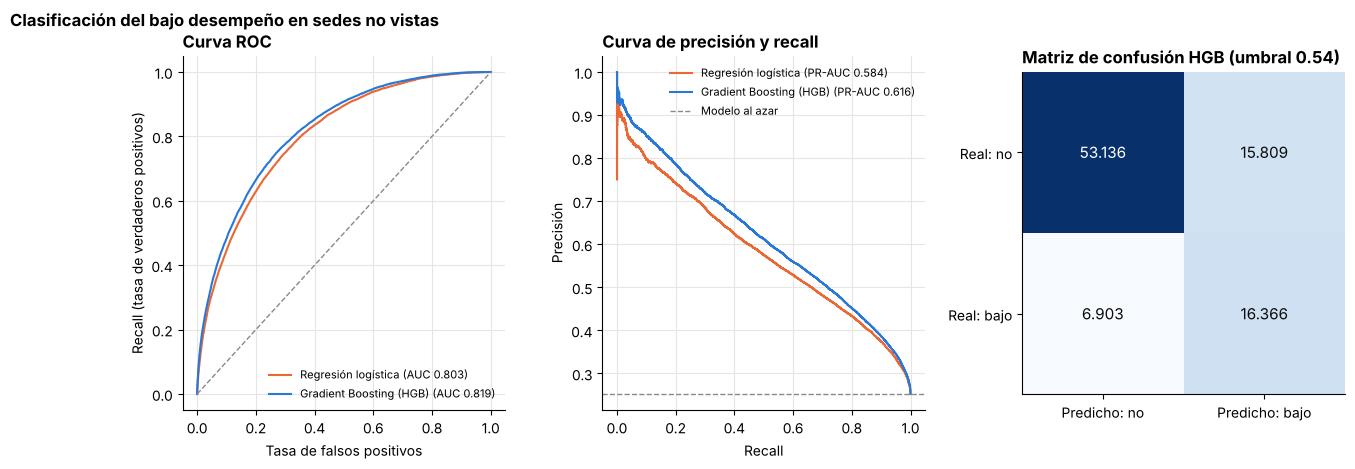

In [ ]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 4.6), gridspec_kw={"wspace": 0.3})
colores_modelos = {"Regresión logística": "#eb6834", "Gradient Boosting (HGB)": "#2a78d6"}
for nombre, prob in probabilidades_test.items():
    fpr, tpr, _ = roc_curve(yb_test, prob)
    ejes[0].plot(fpr, tpr, color=colores_modelos[nombre], label=f"{nombre} (AUC {roc_auc_score(yb_test, prob):.3f})")
    precision, recall, _ = precision_recall_curve(yb_test, prob)
    ejes[1].plot(recall, precision, color=colores_modelos[nombre],
                 label=f"{nombre} (PR-AUC {average_precision_score(yb_test, prob):.3f})")
ejes[0].plot([0, 1], [0, 1], color="#8a8984", linestyle="--", linewidth=1)
ejes[0].set_xlabel("Tasa de falsos positivos")
ejes[0].set_ylabel("Recall (tasa de verdaderos positivos)")
ejes[0].set_title("Curva ROC")
ejes[0].legend(frameon=False, fontsize=8, loc="lower right")
ejes[1].axhline(yb_test.mean(), color="#8a8984", linestyle="--", linewidth=1, label="Modelo al azar")
ejes[1].set_xlabel("Recall")
ejes[1].set_ylabel("Precisión")
ejes[1].set_title("Curva de precisión y recall")
ejes[1].legend(frameon=False, fontsize=8, loc="upper right")

fila = tabla_cm[tabla_cm["modelo"] == "Gradient Boosting (HGB)"].iloc[0]
matriz = np.array([[fila["verdaderos_negativos"], fila["falsos_positivos"]],
                   [fila["falsos_negativos"], fila["verdaderos_positivos"]]])
ejes[2].imshow(matriz, cmap="Blues")
for i in range(2):
    for j in range(2):
        ejes[2].text(j, i, f"{matriz[i, j]:,}".replace(",", "."), ha="center", va="center", fontsize=11,
                     color="white" if matriz[i, j] > matriz.max() / 2 else "#0b0b0b")
ejes[2].set_xticks([0, 1], ["Predicho: no", "Predicho: bajo"])
ejes[2].set_yticks([0, 1], ["Real: no", "Real: bajo"])
ejes[2].grid(False)
ejes[2].set_title(f"Matriz de confusión HGB (umbral {umbrales['Gradient Boosting (HGB)']['umbral_f1']:.2f})")
fig.suptitle("Clasificación del bajo desempeño en sedes no vistas", x=0.01, ha="left", fontweight="bold")
guardar_figura("G8_evaluacion_clasificadores.png")

**Lectura.**

- **Desempeño.** El Gradient Boosting (ROC-AUC = 0,819; PR-AUC = 0,616) supera a la regresión logística (0,803 y 0,584). El PR-AUC más que duplica la referencia de un modelo al azar (0,25).
- **Umbral elegido sin mirar la prueba.** El umbral de máximo F1 (0,54) reduce la proporción de estudiantes marcados del 39,6 % al 34,9 % y sube la precisión al 51 %, con un recall del 70 % y un F1 de 0,59. Si la política prefiere no dejar por fuera a nadie en riesgo, el umbral de 0,45 encuentra al **81 %** de los estudiantes con bajo desempeño en la prueba, muy cerca del 80 % fijado con el entrenamiento: el umbral generaliza bien.
- **Sesgo a tener en cuenta.** Incluso con el umbral ajustado, el modelo marca como riesgo al 67 % de los rurales, cuando la proporción real es del 43,5 %; su recall rural es de 0,89 y su precisión de 0,58. Esto ocurre porque los estudiantes rurales concentran los factores de riesgo. Por eso, para focalizar, conviene **ordenar por probabilidad** (sección 21) en lugar de usar solo la clasificación sí/no.

---
# PARTE D. ¿Qué aportan las variables incorporadas en esta versión?

## 14. Comparación de los modelos con y sin las variables nuevas

Para medir el aporte de las variables que no se usaban, se entrenan los mismos modelos con dos conjuntos de predictores: sin las variables nuevas (las de la versión anterior) y con ellas. Todo lo demás se mantiene igual: la partición, los hiperparámetros y la validación cruzada por sede. Si las variables nuevas aportan información, el error debe bajar en validación cruzada **y** en la prueba.

In [ ]:
columnas_anteriores = [c for c in todas if variable_de_columna(c) not in variables_nuevas]
print(f"Columnas sin las variables nuevas: {len(columnas_anteriores)} | con ellas: {len(todas)}")

filas = []
for nombre, fabrica in [("Regresión lineal", lambda: escalado(LinearRegression())),
                        (nombre_no_lineal, lambda: clone(modelos_regresion[nombre_no_lineal][0]))]:
    for version, columnas in [("Sin variables nuevas", columnas_anteriores), ("Con variables nuevas", todas)]:
        modelo = fabrica()
        cv = validacion_cruzada_regresion(modelo, X_train[columnas], y_train, grupos_train)
        modelo.fit(X_train[columnas], y_train)
        prueba = metricas_regresion(y_test, modelo.predict(X_test[columnas]))
        filas.append({"tarea": "Regresión", "modelo": nombre, "version": version, "CV_R2": cv["CV_R2"],
                      "CV_RMSE": cv["CV_RMSE"], "test_R2": prueba["R2"], "test_RMSE": prueba["RMSE"]})

# Clasificación: Gradient Boosting con y sin las variables nuevas
for version, columnas in [("Sin variables nuevas", columnas_anteriores), ("Con variables nuevas", todas)]:
    modelo = HistGradientBoostingClassifier(**hgb_base, **mejor_hgb).fit(X_train[columnas], yb_train)
    prob = modelo.predict_proba(X_test[columnas])[:, 1]
    filas.append({"tarea": "Clasificación", "modelo": "Gradient Boosting (HGB)", "version": version,
                  "test_ROC_AUC": roc_auc_score(yb_test, prob), "test_PR_AUC": average_precision_score(yb_test, prob)})

ablacion = pd.DataFrame(filas)
guardar_tabla(ablacion, "03_aporte_variables_nuevas.csv")
ablacion

Columnas sin las variables nuevas: 61 | con ellas: 101


,tarea,modelo,version,CV_R2,CV_RMSE,test_R2,test_RMSE,test_ROC_AUC,test_PR_AUC
0,Regresión,Regresión lineal,Sin variables nuevas,0.345,38.752,0.361,38.888,NaN,NaN
1,Regresión,Regresión lineal,Con variables nuevas,0.376,37.809,0.393,37.894,NaN,NaN
2,Regresión,Gradient Boosting,Sin variables nuevas,0.385,37.546,0.397,37.783,NaN,NaN
3,Regresión,Gradient Boosting,Con variables nuevas,0.422,36.408,0.434,36.583,NaN,NaN
4,Clasificación,Gradient Boosting (HGB),Sin variables nuevas,NaN,NaN,NaN,NaN,0.802,0.590
5,Clasificación,Gradient Boosting (HGB),Con variables nuevas,NaN,NaN,NaN,NaN,0.819,0.616


In [ ]:
# Ganancia de cada variable nueva: cuánto empeora el modelo lineal en validación cruzada si se quita solo esa
filas = []
error_completo = validacion_cruzada_regresion(escalado(LinearRegression()), X_train, y_train, grupos_train)["CV_RMSE"]
for variable in variables_nuevas:
    columnas = [c for c in todas if variable_de_columna(c) != variable]
    error = validacion_cruzada_regresion(escalado(LinearRegression()), X_train[columnas], y_train, grupos_train)["CV_RMSE"]
    filas.append({"variable": variable, "grupo": grupo_variable[variable], "aumento_RMSE_al_quitarla": error - error_completo})
aporte_individual = pd.DataFrame(filas).sort_values("aumento_RMSE_al_quitarla", ascending=False)
guardar_tabla(aporte_individual, "03_aporte_individual_variables_nuevas.csv")
aporte_individual

,variable,grupo,aumento_RMSE_al_quitarla
10,lectura_diaria,Estudiante: trabajo y hábitos,0.358
7,situacion_economica,Hogar: alimentación y situación económica,0.296
6,indice_alimentacion,Hogar: alimentación y situación económica,0.094
5,uso_internet,Hogar: conectividad,0.057
4,ocup_padre,Hogar: educación y ocupación de los padres,0.049
3,ocup_madre,Hogar: educación y ocupación de los padres,0.035
9,remuneracion,Estudiante: trabajo y hábitos,0.015
11,estudia_otro_mcpio,Territorio: pobreza y movilidad,0.004
0,sede_secundaria,"Colegio: tipo, jornada y sede",0.004
1,calendario,"Colegio: tipo, jornada y sede",0.003




### **Comparación de resultados con y sin variables nuevas**

**1. Regresión lineal**

La métrica de evaluación utilizada es el R² (coeficiente de determinación). Sin las variables nuevas, el resultado en prueba es de **0,361**, mientras que al incorporarlas aumenta a **0,393**. Esto representa una mejora de **3,2 puntos porcentuales**.

**2. Gradient Boosting**

En este modelo, el R² pasa de **0,397**, sin las variables nuevas, a **0,434** cuando se incorporan. Esto representa una mejora de **3,7 puntos porcentuales**.

Adicionalmente, el RMSE disminuye de **37,8 a 36,6**, lo que significa una reducción de **1,2 puntos** en el error de predicción.

**3. Clasificación (HGB)**

Para el modelo de clasificación, se utiliza la métrica PR-AUC. El resultado pasa de **0,590**, sin las variables nuevas, a **0,616** con su incorporación, lo que representa una mejora de **0,026**.

### Interpretación de los resultados

- **Consistencia de la mejora:** la mejora también aparece en la validación cruzada. El R² de la regresión lineal pasa de **0,345 a 0,376**, por lo que los resultados no parecen depender únicamente de la partición de los datos. Las variables nuevas aumentan cerca de un 9 % la varianza explicada, lo que confirma que su incorporación estaba justificada.

- **Qué variables aportan más:** al retirar las variables una por una, se observa que las que más empeoran el modelo son la lectura por gusto, la situación económica frente al año anterior, la alimentación, el uso de internet y la ocupación de los padres.

- **Qué variables casi no aportan a la predicción:** la sede secundaria, el calendario, la movilidad, la focalización por Sisbén y la migración modifican el RMSE en menos de 0,01 puntos. Esto ocurre porque parte de su información ya está representada en otras variables, como sucede con el Sisbén, cuyo contenido también se refleja en el estrato y los bienes del hogar.

- **Por qué no se descartan:** aunque algunas variables aportan poco a la predicción individual, se mantienen porque son pocas columnas, Lasso no las elimina y también sirven para la interpretación económica. Además, varias son significativas en la sección 15 y la movilidad forma parte del grupo territorial de la descomposición.

---
# PARTE E. Interpretación económica: ¿qué explica la brecha?

Para la interpretación se usa la muestra completa de modelamiento(entrenamiento + prueba, ya transformadas con el preprocesador ajustado en entrenamiento), porque aquí el objetivo ya no es predecir sino explicar.



In [ ]:
completa = pd.concat([train, test], ignore_index=True)
X_completa = pd.concat([X_train, X_test], ignore_index=True)
y_completa = completa["punt_global"].values
print("Muestra completa:", X_completa.shape)

Muestra completa: (449695, 101)


## 15. Regresión lineal (MCO) con errores estándar agrupados por sede



In [ ]:
def mco_errores_agrupados(X, y, grupos):
    """
    Estima una regresión lineal (MCO) con errores estándar agrupados por conglomerado.

    Parámetros:
        X (DataFrame): variables explicativas (sin constante).
        y (array): variable dependiente.
        grupos (array): conglomerado de cada observación (la sede).

    Retorna:
        DataFrame: coeficiente, error estándar, estadístico t e intervalo de confianza del 95 %.
    """
    Xc = np.column_stack([np.ones(len(X)), X.values])      # agregar la constante
    nombres = ["constante"] + list(X.columns)
    XtX_inv = np.linalg.pinv(Xc.T @ Xc)
    beta = XtX_inv @ Xc.T @ y
    residuos = y - Xc @ beta

    # Suma, dentro de cada sede, de (x_i * u_i): una fila por sede
    puntajes = pd.DataFrame(Xc * residuos[:, None]).groupby(grupos).sum().values
    n, k, G = Xc.shape[0], Xc.shape[1], puntajes.shape[0]
    varianza = XtX_inv @ (puntajes.T @ puntajes) @ XtX_inv * (G / (G - 1)) * ((n - 1) / (n - k))
    error_estandar = np.sqrt(np.diag(varianza))

    r2 = 1 - (residuos @ residuos) / ((y - y.mean()) @ (y - y.mean()))
    print(f"R² = {r2:.3f} | estudiantes = {n:,} | sedes = {G:,}")
    return pd.DataFrame({"variable": nombres, "coeficiente": beta, "error_estandar": error_estandar,
                         "t": beta / error_estandar, "ic95_inf": beta - 1.96 * error_estandar,
                         "ic95_sup": beta + 1.96 * error_estandar})

In [ ]:
tabla_mco = mco_errores_agrupados(X_completa, y_completa, completa["sede"].values)
tabla_mco["grupo"] = ["—"] + [grupo_de_columna(c) for c in X_completa.columns]
guardar_tabla(tabla_mco, "03_mco_coeficientes.csv")

brecha_bruta = y_completa[completa["rural"] == 0].mean() - y_completa[completa["rural"] == 1].mean()
print(f"Brecha bruta en la muestra: {brecha_bruta:.2f} puntos")
principales = ["rural", "internet=Sí", "computador=Sí", "nse_colegio=NSE 3", "nse_colegio=NSE 4",
               "educ_madre=Profesional completa", "jornada=Única", "etnia=Sí", "edad", "ipm_zona",
               "indice_bienes_pca"]
tabla_mco[tabla_mco["variable"].isin(principales)]

R² = 0.381 | estudiantes = 449,695 | sedes = 10,413
Brecha bruta en la muestra: 28.24 puntos


,variable,coeficiente,error_estandar,t,ic95_inf,ic95_sup,grupo
1,rural,3.917,0.750,5.224,2.447,5.386,Ruralidad (efecto residual)
10,jornada=Única,1.538,0.487,3.159,0.584,2.492,"Colegio: tipo, jornada y sede"
22,nse_colegio=NSE 3,14.172,0.877,16.155,12.453,15.892,Colegio: NSE de los pares
23,nse_colegio=NSE 4,43.624,1.397,31.217,40.885,46.363,Colegio: NSE de los pares
36,educ_madre=Profesional completa,8.502,0.325,26.143,7.864,9.139,Hogar: educación y ocupación de los padres
63,internet=Sí,5.237,0.216,24.282,4.815,5.660,Hogar: conectividad
65,computador=Sí,4.993,0.179,27.895,4.642,5.344,Hogar: conectividad
76,etnia=Sí,-11.402,0.650,-17.553,-12.675,-10.129,Estudiante: características
91,indice_bienes_pca,-2.536,0.068,-37.094,-2.670,-2.402,Hogar: nivel socioeconómico
96,edad,-8.330,0.087,-95.845,-8.501,-8.160,Estudiante: características


In [ ]:
# Coeficientes de las variables incorporadas en esta versión
tabla_mco[tabla_mco["variable"].map(lambda v: v != "constante" and variable_de_columna(v) in variables_nuevas)]

,variable,coeficiente,error_estandar,t,ic95_inf,ic95_sup,grupo
2,sede_secundaria,-2.198,0.697,-3.154,-3.563,-0.832,"Colegio: tipo, jornada y sede"
3,focalizado_sisben,-1.152,0.241,-4.783,-1.624,-0.680,Hogar: nivel socioeconómico
4,migrante,-1.242,0.914,-1.359,-3.033,0.549,Estudiante: características
5,estudia_otro_mcpio,2.976,0.673,4.422,1.657,4.296,Territorio: pobreza y movilidad
6,presenta_otro_mcpio,-1.737,0.500,-3.472,-2.718,-0.756,Territorio: pobreza y movilidad
19,calendario=B,-2.632,3.868,-0.680,-10.213,4.950,"Colegio: tipo, jornada y sede"
20,calendario=Otro,-13.802,1.838,-7.510,-17.405,-10.200,"Colegio: tipo, jornada y sede"
48,ocup_madre=Agricultor o jornalero,-1.510,0.371,-4.066,-2.238,-0.782,Hogar: educación y ocupación de los padres
49,ocup_madre=Empleado administrativo o vendedor,-3.408,0.190,-17.930,-3.781,-3.036,Hogar: educación y ocupación de los padres
50,ocup_madre=Negocio pequeño o cuenta propia,-2.719,0.174,-15.587,-3.061,-2.377,Hogar: educación y ocupación de los padres


**Lectura de los coeficientes principales** (cada uno manteniendo constante todo lo demás):

- **Zona rural: +3,9 puntos** (IC 95 %: 2,4 a 5,4). Con las mismas características, los estudiantes rurales obtienen igual o algo más que los urbanos. La desventaja rural es de composición, no de «ser rural».
- **NSE del colegio:** estar en un colegio de NSE 4 se asocia con 44 puntos más que en uno de NSE 1. Refleja la segregación socioeconómica escolar.
- **Conectividad:** tener internet se asocia con 5,2 puntos más, tener computador con 5,0 y navegar entre 1 y 3 horas al día con 6,8 más que no navegar.
- **Variables incorporadas:**
  - **Hallazgo 1. La paradoja de la situación económica se mantiene con todos los controles.** Frente a quienes dicen que su situación está igual, los que reportan que empeoró obtienen **8,2 puntos más** y los que dicen que mejoró, **7,3 puntos menos**. Como ya se controla por estrato, bienes, educación y ocupación de los padres, no es un efecto de composición: la pregunta parece medir la exposición al choque de la pandemia (más fuerte en hogares con ingresos formales o urbanos) y no la pobreza del hogar. No debe leerse como un efecto causal.
  - **Hallazgo 2. Ser hijo de agricultor no es una desventaja una vez se controla por el resto.** Todas las demás ocupaciones del padre tienen coeficientes negativos frente a «agricultor o jornalero» (entre −1,6 y −7,2 puntos). La desventaja bruta de estos estudiantes (gráfica 6) se explica por la menor educación y los menores ingresos de sus hogares, no por la ocupación agrícola en sí.
  - **Lectura por gusto:** leer más de 2 horas al día se asocia con 18,5 puntos más que no leer, y leer entre 30 y 60 minutos con 13,0 más. Es el hábito con la asociación más fuerte.
  - **Alimentación:** cada punto del índice se asocia con 1,5 puntos más; pasar de 0 a 9 equivale a cerca de 13 puntos.
  - **Focalización y sede:** estar focalizado por el Sisbén (−1,2), estudiar en una sede secundaria (−2,2) y presentar el examen en otro municipio (−1,7) se asocian con puntajes más bajos; vivir en un municipio distinto al del colegio, con 3,0 puntos más. Ser migrante venezolano no tiene una asociación significativa (−1,2; IC de −3,0 a 0,5).
- **Cuidado:** el índice de bienes sale negativo (−2,5) cuando se controlan a la vez el estrato, los libros, la conectividad y la educación de los padres. Es un efecto de la correlación entre variables que miden lo mismo; por eso las secciones 16 y 17 analizan grupos de factores.

## 16. Descomposición de Oaxaca-Blinder

Esta técnica, clásica en economía laboral, divide la brecha en dos partes:



- **Parte explicada:** cuánto de la brecha se debe a que los estudiantes rurales tienen **características distintas** (menos conectividad, colegios de menor NSE, etc.). Se calcula variable por variable y se suma por grupo de factores.
- **Parte no explicada:** la diferencia que queda aun con las mismas características.


In [ ]:
def oaxaca_blinder(X, y, es_rural, grupos_columnas):
    """
    Descomposición de Oaxaca-Blinder en dos partes.

    Parámetros:
        X (DataFrame): características (SIN la variable rural).
        y (array): puntaje global.
        es_rural (array): 1 si el estudiante es rural.
        grupos_columnas (list): grupo de factores de cada columna de X.

    Retorna:
        dict: brecha, parte explicada y no explicada con tres referencias, y el detalle por grupo.
    """
    Xc = np.column_stack([np.ones(len(X)), X.values])
    urbano, rural = es_rural == 0, es_rural == 1

    def mco(A, b):
        return np.linalg.pinv(A.T @ A) @ (A.T @ b)

    beta_urbano = mco(Xc[urbano], y[urbano])
    beta_rural = mco(Xc[rural], y[rural])
    beta_agrupado = mco(np.column_stack([Xc, es_rural]), y)[:-1]   # regresión conjunta con indicador rural

    diferencia_medias = Xc[urbano].mean(axis=0) - Xc[rural].mean(axis=0)
    brecha = y[urbano].mean() - y[rural].mean()
    resultado = {"brecha": brecha}
    for referencia, beta in [("agrupados", beta_agrupado), ("urbanos", beta_urbano), ("rurales", beta_rural)]:
        contribucion = diferencia_medias * beta
        resultado[f"explicada_{referencia}"] = contribucion.sum()
        resultado[f"no_explicada_{referencia}"] = brecha - contribucion.sum()
        resultado[f"detalle_{referencia}"] = pd.Series(contribucion[1:], index=X.columns).groupby(grupos_columnas).sum()
    return resultado

In [ ]:
X_oaxaca = X_completa.drop(columns=["rural"])
grupos_oaxaca = [grupo_de_columna(c) for c in X_oaxaca.columns]
ob = oaxaca_blinder(X_oaxaca, y_completa, completa["rural"].values, grupos_oaxaca)
print(f"Brecha: {ob['brecha']:.2f} | explicada: {ob['explicada_agrupados']:.2f} "
      f"({ob['explicada_agrupados'] / ob['brecha'] * 100:.1f} %) | no explicada: {ob['no_explicada_agrupados']:.2f}")

Brecha: 28.24 | explicada: 32.16 (113.9 %) | no explicada: -3.92


Intervalos de confianza por bootstrap de sedes. Para saber qué tan precisa es cada parte, se repite la descomposición 50 veces. En cada repetición se toma una muestra de sedes con reemplazo, que conserva junta a cada sede, y al final se toman los percentiles 2,5 y 97,5 de los resultados.

In [ ]:
generador = np.random.default_rng(SEMILLA)
sedes_unicas, indice_sede = np.unique(completa["sede"].values, return_inverse=True)
filas_por_sede = pd.Series(np.arange(len(completa))).groupby(indice_sede).apply(np.array).values

replicas = []
for b in range(50):
    sedes_elegidas = generador.integers(0, len(sedes_unicas), len(sedes_unicas))
    filas = np.concatenate([filas_por_sede[i] for i in sedes_elegidas])
    r = oaxaca_blinder(X_oaxaca.iloc[filas].reset_index(drop=True), y_completa[filas],
                       completa["rural"].values[filas], grupos_oaxaca)
    replicas.append({"brecha": r["brecha"], "explicada": r["explicada_agrupados"],
                     "no_explicada": r["no_explicada_agrupados"], **r["detalle_agrupados"].to_dict()})
replicas = pd.DataFrame(replicas)

componentes = [("Brecha total (urbano − rural)", ob["brecha"], "brecha"),
               ("Parte explicada (características)", ob["explicada_agrupados"], "explicada")]
for grupo in grupos[1:]:
    componentes.append((f"   · {grupo}", ob["detalle_agrupados"][grupo], grupo))
componentes.append(("Parte no explicada", ob["no_explicada_agrupados"], "no_explicada"))

tabla_oaxaca = pd.DataFrame([{"componente": nombre, "puntos": valor, "pct_brecha": valor / ob["brecha"] * 100,
                              "ic95_inf": np.percentile(replicas[clave], 2.5),
                              "ic95_sup": np.percentile(replicas[clave], 97.5)}
                             for nombre, valor, clave in componentes])
guardar_tabla(tabla_oaxaca, "03_oaxaca_blinder.csv")
tabla_oaxaca

,componente,puntos,pct_brecha,ic95_inf,ic95_sup
0,Brecha total (urbano − rural),28.245,100.000,26.620,29.341
1,Parte explicada (características),32.162,113.868,30.874,33.487
2,"· Colegio: tipo, jornada y sede",1.078,3.817,0.577,1.507
3,· Hogar: nivel socioeconómico,0.290,1.026,0.046,0.471
4,· Estudiante: características,2.893,10.244,2.558,3.179
5,· Territorio: pobreza y movilidad,10.157,35.960,8.941,11.536
6,· Colegio: NSE de los pares,7.133,25.253,6.471,7.827
7,· Hogar: educación y ocupación de los padres,1.963,6.950,1.723,2.128
8,· Hogar: conectividad,4.806,17.015,4.598,5.051
9,· Hogar: alimentación y situación económica,2.233,7.905,2.160,2.348


In [ ]:
# Sensibilidad a la referencia de los coeficientes
tabla_sensibilidad = pd.DataFrame([{"referencia": f"Coeficientes {r}", "explicada": ob[f"explicada_{r}"],
                                    "no_explicada": ob[f"no_explicada_{r}"],
                                    "pct_explicado": ob[f"explicada_{r}"] / ob["brecha"] * 100}
                                   for r in ["agrupados", "urbanos", "rurales"]])
guardar_tabla(tabla_sensibilidad, "03_oaxaca_sensibilidad.csv")
tabla_sensibilidad

,referencia,explicada,no_explicada,pct_explicado
0,Coeficientes agrupados,32.162,-3.917,113.868
1,Coeficientes urbanos,31.777,-3.532,112.504
2,Coeficientes rurales,32.363,-4.118,114.581


In [ ]:
# Parte explicada por grupo: sin las variables nuevas frente a con ellas
columnas_oaxaca_anteriores = [c for c in X_oaxaca.columns if c in columnas_anteriores]
ob_anterior = oaxaca_blinder(X_oaxaca[columnas_oaxaca_anteriores], y_completa, completa["rural"].values,
                             [grupo_de_columna(c) for c in columnas_oaxaca_anteriores])
comparacion_oaxaca = pd.DataFrame({"sin_variables_nuevas": ob_anterior["detalle_agrupados"],
                                   "con_variables_nuevas": ob["detalle_agrupados"]}).reindex(grupos[1:]).fillna(0)
comparacion_oaxaca.loc["Total explicado"] = [ob_anterior["explicada_agrupados"], ob["explicada_agrupados"]]
comparacion_oaxaca.loc["No explicada"] = [ob_anterior["no_explicada_agrupados"], ob["no_explicada_agrupados"]]
comparacion_oaxaca["cambio"] = comparacion_oaxaca["con_variables_nuevas"] - comparacion_oaxaca["sin_variables_nuevas"]
guardar_tabla(comparacion_oaxaca, "03_oaxaca_con_y_sin_variables_nuevas.csv", index=True)
comparacion_oaxaca

,sin_variables_nuevas,con_variables_nuevas,cambio
"Colegio: tipo, jornada y sede",1.117,1.078,-0.039
Hogar: nivel socioeconómico,0.400,0.290,-0.110
Estudiante: características,3.044,2.893,-0.151
Territorio: pobreza y movilidad,9.457,10.157,0.699
Colegio: NSE de los pares,8.074,7.133,-0.941
Hogar: educación y ocupación de los padres,3.627,1.963,-1.664
Hogar: conectividad,4.016,4.806,0.790
Hogar: alimentación y situación económica,0.000,2.233,2.233
Estudiante: trabajo y hábitos,1.642,1.609,-0.033
Total explicado,31.378,32.162,0.784


**Gráfica 9. Descomposición de Oaxaca-Blinder de la brecha.** Es una gráfica de cascada: cada barra de color suma lo que aporta un grupo de factores a la brecha. La barra gris es la parte no explicada y la barra negra, la brecha total.

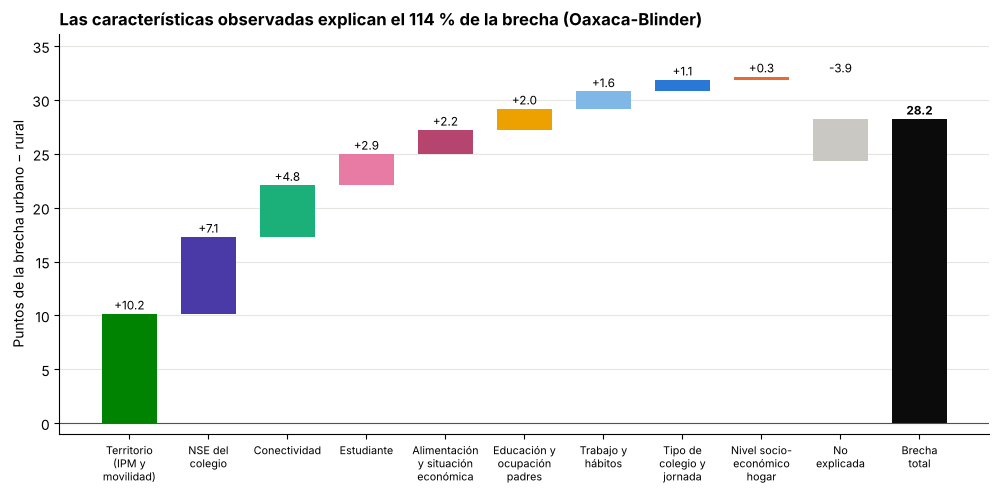

In [ ]:
colores_grupos = {"Ruralidad (efecto residual)": "#8a8984", "Colegio: tipo, jornada y sede": "#2a78d6",
                  "Colegio: NSE de los pares": "#4a3aa7", "Hogar: nivel socioeconómico": "#eb6834",
                  "Hogar: educación y ocupación de los padres": "#eda100", "Hogar: conectividad": "#1baf7a",
                  "Hogar: alimentación y situación económica": "#b5446e",
                  "Estudiante: características": "#e87ba4", "Estudiante: trabajo y hábitos": "#7fb8e6",
                  "Territorio: pobreza y movilidad": "#008300"}
etiquetas_cortas = {"Territorio: pobreza y movilidad": "Territorio\n(IPM y\nmovilidad)",
                    "Colegio: NSE de los pares": "NSE del\ncolegio", "Estudiante: características": "Estudiante",
                    "Estudiante: trabajo y hábitos": "Trabajo y\nhábitos", "Hogar: conectividad": "Conectividad",
                    "Hogar: educación y ocupación de los padres": "Educación y\nocupación\npadres",
                    "Colegio: tipo, jornada y sede": "Tipo de\ncolegio y\njornada",
                    "Hogar: nivel socioeconómico": "Nivel socio-\neconómico\nhogar",
                    "Hogar: alimentación y situación económica": "Alimentación\ny situación\neconómica"}
detalle = ob["detalle_agrupados"].sort_values(ascending=False)
plt.figure(figsize=(12, 5.2))
acumulado = 0
etiquetas = []
for i, (grupo, valor) in enumerate(detalle.items()):
    plt.bar(i, valor, bottom=acumulado if valor >= 0 else acumulado + valor, color=colores_grupos[grupo], width=0.7)
    plt.text(i, acumulado + max(valor, 0) + 0.4, f"{valor:+.1f}", ha="center", fontsize=8.5)
    acumulado += valor
    etiquetas.append(etiquetas_cortas[grupo])
n = len(detalle)
no_explicada = ob["no_explicada_agrupados"]
plt.bar(n, no_explicada, bottom=acumulado if no_explicada >= 0 else acumulado + no_explicada, color="#c9c8c3", width=0.7)
plt.text(n, acumulado + max(no_explicada, 0) + 0.4, f"{no_explicada:+.1f}", ha="center", fontsize=8.5)
plt.bar(n + 1, ob["brecha"], color="#0b0b0b", width=0.7)
plt.text(n + 1, ob["brecha"] + 0.4, f"{ob['brecha']:.1f}", ha="center", fontsize=8.5, fontweight="bold")
plt.xticks(range(n + 2), etiquetas + ["No\nexplicada", "Brecha\ntotal"], fontsize=7.8)
plt.ylim(min(0, detalle.min()) - 1, max(acumulado, ob["brecha"]) + 4)
plt.axhline(0, color="#52514e", linewidth=0.8)
plt.grid(axis="x", visible=False)
plt.ylabel("Puntos de la brecha urbano − rural")
plt.title(f"Las características observadas explican el {ob['explicada_agrupados'] / ob['brecha'] * 100:.0f} % de la brecha (Oaxaca-Blinder)")
guardar_figura("G9_oaxaca_blinder.png")

**Lectura.**

- **Las características explican más que toda la brecha.** Explican 32,2 de los 28,2 puntos (114 %). Si los estudiantes rurales tuvieran las características de los urbanos, la brecha no solo desaparecería: se invertiría levemente. Por eso la parte no explicada es negativa (−3,9 puntos, IC 95 %: −5,5 a −3,1) y coincide con el coeficiente rural positivo de la sección 15.
- **Aportes principales:** territorio (IPM y movilidad) 10,2 puntos (36 %); NSE del colegio 7,1 (25 %); conectividad 4,8 (17 %); características del estudiante 2,9 (10 %); alimentación y situación económica 2,2 (8 %); educación y ocupación de los padres 2,0 (7 %); trabajo y hábitos 1,6 (6 %).
- **Qué cambia con las variables nuevas** (tabla anterior):
  - El grupo nuevo de **alimentación y situación económica aporta 2,2 puntos**: unos 1,2 por la alimentación (los rurales tienen en promedio 0,8 puntos menos en el índice) y unos 1,0 por la situación económica (los urbanos reportan más deterioro).
  - La **conectividad sube de 4,0 a 4,8** puntos al agregar el uso diario de internet: no basta con medir si hay internet en la casa, también importa cuánto se usa.
  - El grupo de **educación y ocupación de los padres baja de 3,6 a 2,0**: la mayor proporción de padres agricultores en lo rural, que con los controles no es una desventaja (sección 15), resta cerca de 1,5 puntos.
  - El **NSE del colegio baja de 8,1 a 7,1**: parte de lo que antes se atribuía a la composición del colegio corresponde en realidad a la alimentación y la situación económica de los hogares.
- **Robustez.** Con coeficientes urbanos o rurales, la parte explicada sigue entre 112 % y 115 %.

## 17. Descomposición de Shapley sobre el Random Forest

Oaxaca-Blinder supone un modelo lineal. Para comprobar que la conclusión no depende de ese supuesto, se descompone la brecha que predicen el mejor modelo no lineal (elegido en la sección 9) y la regresión lineal, con valores de Shapley sobre los 10 grupos de factores.

Se toman 5.000 estudiantes rurales de prueba y a cada uno se le asigna al azar un estudiante urbano. Se reemplazan las características de esos grupos del rural por las de su pareja urbana y se mide cuánto sube la predicción promedio.



Así el resultado no depende del orden. Se repite con 3 emparejamientos aleatorios distintos para comprobar que es estable.Con 10 grupos hay $2^{10} = 1.024$ combinaciones posibles, así que cada repetición evalúa 1.024 predicciones de 5.000 estudiantes.

In [ ]:
def shapley_por_grupos(modelo, X_rural, X_urbano, columnas_por_grupo):
    """
    Descomposición de Shapley de la brecha predicha por un modelo, por grupos de factores.

    Parámetros:
        modelo: modelo entrenado con método predict.
        X_rural (DataFrame): estudiantes rurales.
        X_urbano (DataFrame): estudiantes urbanos emparejados fila a fila con los rurales.
        columnas_por_grupo (dict): grupo -> lista de columnas.

    Retorna:
        dict: aporte de cada grupo (en puntos) y la brecha predicha total.
    """
    lista_grupos = list(columnas_por_grupo)
    k = len(lista_grupos)
    base = modelo.predict(X_rural).mean()
    valor = {}   # v(S) para cada conjunto de grupos S

    for tamano in range(k + 1):
        for conjunto in combinations(lista_grupos, tamano):
            X_mod = X_rural.copy()
            for grupo in conjunto:
                columnas = columnas_por_grupo[grupo]
                X_mod[columnas] = X_urbano[columnas].values
            valor[conjunto] = modelo.predict(X_mod).mean() - base

    aportes = {}
    for grupo in lista_grupos:
        otros = [g for g in lista_grupos if g != grupo]
        total = 0
        for tamano in range(k):
            peso = factorial(tamano) * factorial(k - tamano - 1) / factorial(k)
            for conjunto in combinations(otros, tamano):
                con_grupo = tuple(g for g in lista_grupos if g in conjunto or g == grupo)
                total += peso * (valor[con_grupo] - valor[conjunto])
        aportes[grupo] = total
    aportes["brecha_predicha"] = valor[tuple(lista_grupos)]
    return aportes

In [ ]:
columnas_por_grupo = {g: [c for c in X_test.columns if grupo_de_columna(c) == g] for g in grupos}
X_test_rural = X_test[test["rural"] == 1].reset_index(drop=True)
X_test_urbano = X_test[test["rural"] == 0].reset_index(drop=True)

filas = []
for semilla in range(3):
    generador_s = np.random.default_rng(SEMILLA + semilla)
    filas_rurales = generador_s.choice(len(X_test_rural), 5000, replace=False)
    filas_urbanas = generador_s.choice(len(X_test_urbano), 5000, replace=True)
    X_r = X_test_rural.iloc[filas_rurales].reset_index(drop=True)
    X_u = X_test_urbano.iloc[filas_urbanas].reset_index(drop=True)
    for nombre, modelo in [(nombre_no_lineal, modelo_no_lineal), ("Regresión lineal", modelo_lineal)]:
        aportes = shapley_por_grupos(modelo, X_r, X_u, columnas_por_grupo)
        for grupo in grupos:
            filas.append({"modelo": nombre, "semilla": semilla, "grupo": grupo, "puntos": aportes[grupo],
                          "brecha_predicha": aportes["brecha_predicha"]})
        print(f"Emparejamiento {semilla + 1}, {nombre}: brecha predicha = {aportes['brecha_predicha']:.2f}")

shapley = pd.DataFrame(filas).groupby(["modelo", "grupo"]).agg(
    puntos=("puntos", "mean"), desviacion_entre_semillas=("puntos", "std"),
    brecha_predicha=("brecha_predicha", "mean")).reset_index()
shapley["pct_brecha_predicha"] = shapley["puntos"] / shapley["brecha_predicha"] * 100
shapley = shapley.sort_values(["modelo", "puntos"], ascending=[True, False])
guardar_tabla(shapley, "03_shapley_por_grupo.csv")
shapley[shapley["modelo"] == nombre_no_lineal]

Emparejamiento 1, Gradient Boosting: brecha predicha = 26.65
Emparejamiento 1, Regresión lineal: brecha predicha = 26.84
Emparejamiento 2, Gradient Boosting: brecha predicha = 25.51
Emparejamiento 2, Regresión lineal: brecha predicha = 26.04
Emparejamiento 3, Gradient Boosting: brecha predicha = 24.83
Emparejamiento 3, Regresión lineal: brecha predicha = 25.25


,modelo,grupo,puntos,desviacion_entre_semillas,brecha_predicha,pct_brecha_predicha
0,Gradient Boosting,Colegio: NSE de los pares,7.103,0.259,25.663,27.677
5,Gradient Boosting,Hogar: conectividad,4.820,0.142,25.663,18.781
2,Gradient Boosting,Estudiante: características,2.381,0.175,25.663,9.276
8,Gradient Boosting,Ruralidad (efecto residual),2.302,0.045,25.663,8.971
6,Gradient Boosting,Hogar: educación y ocupación de los padres,2.110,0.106,25.663,8.221
9,Gradient Boosting,Territorio: pobreza y movilidad,2.039,0.175,25.663,7.945
4,Gradient Boosting,Hogar: alimentación y situación económica,1.951,0.168,25.663,7.603
3,Gradient Boosting,Estudiante: trabajo y hábitos,1.449,0.047,25.663,5.645
1,Gradient Boosting,"Colegio: tipo, jornada y sede",0.776,0.023,25.663,3.025
7,Gradient Boosting,Hogar: nivel socioeconómico,0.733,0.089,25.663,2.856



El Gradient Boosting confirma las conclusiones principales de Oaxaca con un modelo no lineal, con un matiz:

- **Coinciden:** el NSE del colegio es el primer factor (7,1 puntos, 28 % de la brecha predicha), seguido de la conectividad (4,8 puntos, 19 %). El grupo nuevo de alimentación y situación económica aporta 2,0 puntos (8 %), casi lo mismo que en Oaxaca (2,2).
- **Matiz: el reparto entre territorio y ruralidad.** En Oaxaca el territorio aporta 10,2 puntos y la ruralidad −3,9; en el Gradient Boosting, 2,0 y +2,3. La razón es que el IPM se mide por departamento y zona (66 valores), así que está casi determinado por la zona: el modelo de árboles lo usa como un identificador del territorio y reparte su aporte de otra forma. Lo que sí es robusto es la **suma**: el contexto territorial (zona + IPM + movilidad) explica entre 4 y 6 puntos de la brecha en los dos métodos.
- **Estabilidad:** la desviación entre los tres emparejamientos es menor que 0,3 puntos en todos los grupos, así que el resultado no depende del sorteo.

## 18. Importancia de las variables por permutación

Mide cuánto empeora el modelo si se «desordena» al azar una variable, lo que rompe su relación con el puntaje. Si el error sube mucho, la variable era importante. Todas las dummies de una misma variable (y su indicador de faltante) se permutan juntas, para medir la importancia de la variable completa.

Se calcula sobre 12.000 estudiantes de prueba y 3 repeticiones, para el mejor modelo de regresión no lineal (aumento del RMSE) y el Gradient Boosting de clasificación (caída del ROC-AUC).

**Nota sobre SHAP y XGBoost.** En el entorno donde se ejecutó el proyecto no fue posible instalar las librerías `xgboost` ni `shap`. Por eso se usan sus equivalentes de scikit-learn: `HistGradientBoosting` (el mismo algoritmo de *gradient boosting* por histogramas) y, para interpretar, la importancia por permutación (cuánto importa cada variable), la dependencia parcial (en qué dirección actúa, sección 19) y una descomposición de Shapley por grupos programada a mano (sección 17).

In [ ]:
nombres_legibles = {
    "rural": "Zona rural", "naturaleza": "Naturaleza del colegio", "jornada": "Jornada",
    "caracter": "Carácter del colegio", "genero_colegio": "Género del colegio", "bilingue": "Colegio bilingüe",
    "calendario": "Calendario ★", "sede_secundaria": "Sede secundaria ★",
    "nse_colegio": "NSE del colegio (pares)", "estrato": "Estrato", "libros": "Libros en el hogar",
    "indice_bienes_pca": "Índice de bienes (PCA)", "focalizado_sisben": "Focalizado por Sisbén ★",
    "educ_madre": "Educación de la madre", "educ_padre": "Educación del padre",
    "ocup_madre": "Ocupación de la madre ★", "ocup_padre": "Ocupación del padre ★",
    "internet": "Internet en el hogar", "computador": "Computador en el hogar", "uso_internet": "Uso de internet ★",
    "indice_alimentacion": "Índice de alimentación ★", "situacion_economica": "Situación económica ★",
    "genero": "Género", "etnia": "Pertenencia étnica", "migrante": "Migrante venezolano ★",
    "trabajo_horas": "Horas de trabajo", "remuneracion": "Remuneración del trabajo ★",
    "lectura_diaria": "Lectura por gusto ★", "hacinamiento": "Hacinamiento", "personas_hogar": "Personas en el hogar",
    "edad": "Edad", "ipm_zona": "IPM dpto.×zona (DANE)", "estudia_otro_mcpio": "Vive en otro municipio ★",
    "presenta_otro_mcpio": "Presenta en otro municipio ★",
}

In [ ]:
def importancia_permutacion(funcion_error, X, y, repeticiones, generador):
    """
    Importancia por permutación agrupada por variable original.

    Parámetros:
        funcion_error (función): recibe (X, y) y retorna un error (mayor = peor).
        X (DataFrame), y (array): datos de evaluación.
        repeticiones (int): veces que se permuta cada variable.
        generador: generador de números aleatorios de NumPy.

    Retorna:
        DataFrame: aumento promedio del error al permutar cada variable.
    """
    error_base = funcion_error(X, y)
    columnas_por_variable = {}
    for columna in X.columns:
        columnas_por_variable.setdefault(variable_de_columna(columna), []).append(columna)

    filas = []
    for variable, columnas in columnas_por_variable.items():
        aumentos = []
        for _ in range(repeticiones):
            X_perm = X.copy()
            orden = generador.permutation(len(X))
            X_perm[columnas] = X[columnas].values[orden]
            aumentos.append(funcion_error(X_perm, y) - error_base)
        filas.append({"variable": nombres_legibles.get(variable, variable), "grupo": grupo_de_columna(columnas[0]),
                      "importancia": np.mean(aumentos), "desviacion": np.std(aumentos)})
    return pd.DataFrame(filas).sort_values("importancia", ascending=False).reset_index(drop=True)

In [ ]:
generador = np.random.default_rng(SEMILLA + 100)
muestra = generador.choice(len(X_test), 12000, replace=False)
X_muestra = X_test.iloc[muestra].reset_index(drop=True)
y_muestra = y_test[muestra]
yb_muestra = (y_muestra < umbral_bajo).astype(int)

importancia_reg = importancia_permutacion(
    lambda X, y: np.sqrt(mean_squared_error(y, modelo_no_lineal.predict(X))), X_muestra, y_muestra, 3, generador)
modelo_hgb = modelos_clasificacion["Gradient Boosting (HGB)"]
importancia_hgb = importancia_permutacion(
    lambda X, y: -roc_auc_score(y, modelo_hgb.predict_proba(X)[:, 1]), X_muestra, yb_muestra, 3, generador)

guardar_tabla(importancia_reg, "03_importancia_permutacion_regresion.csv")
guardar_tabla(importancia_hgb, "03_importancia_permutacion_clasificacion.csv")
pd.concat([importancia_reg.head(12)[["variable", "importancia"]].rename(columns={"variable": f"{nombre_no_lineal} (aumento RMSE)"}),
           importancia_hgb.head(12)[["variable", "importancia"]].rename(columns={"variable": "HGB (caída ROC-AUC)"})],
          axis=1)

,Gradient Boosting (aumento RMSE),importancia,HGB (caída ROC-AUC),importancia
0,NSE del colegio (pares),3.668,NSE del colegio (pares),0.030
1,Edad,1.954,Edad,0.026
2,IPM dpto.×zona (DANE),1.236,IPM dpto.×zona (DANE),0.021
3,Género,0.952,Lectura por gusto ★,0.010
4,Lectura por gusto ★,0.853,Estrato,0.009
5,Situación económica ★,0.639,Género,0.009
6,Horas de trabajo,0.630,Situación económica ★,0.008
7,Libros en el hogar,0.581,Libros en el hogar,0.006
8,Índice de alimentación ★,0.528,Índice de bienes (PCA),0.006
9,Educación de la madre,0.509,Horas de trabajo,0.005


**Gráfica 10. Importancia por permutación de las 12 variables más importantes.** Muestra qué variables usa más cada modelo para predecir, con el color del grupo de factores. Las variables marcadas con ★ se incorporan en esta versión.

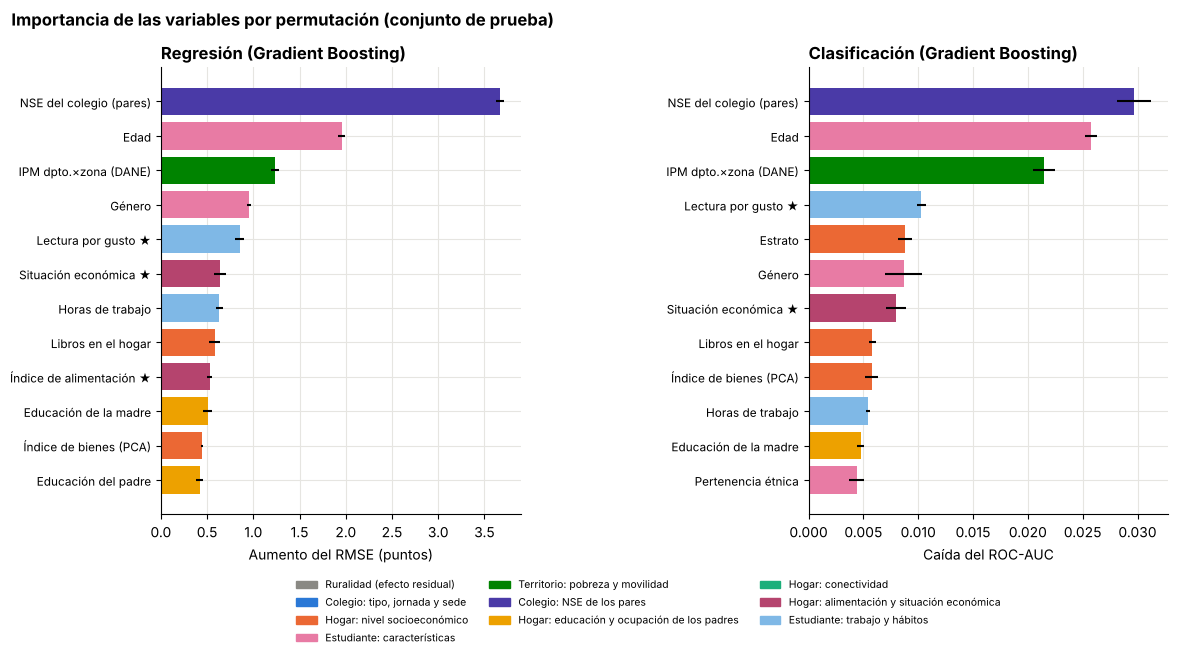

In [ ]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 5.8), gridspec_kw={"wspace": 0.8})
for eje, tabla, titulo, etiqueta in [(ejes[0], importancia_reg, f"Regresión ({nombre_no_lineal})", "Aumento del RMSE (puntos)"),
                                     (ejes[1], importancia_hgb, "Clasificación (Gradient Boosting)", "Caída del ROC-AUC")]:
    datos = tabla.head(12).iloc[::-1]
    eje.barh(range(len(datos)), datos["importancia"], xerr=datos["desviacion"],
             color=[colores_grupos[g] for g in datos["grupo"]])
    eje.set_yticks(range(len(datos)))
    eje.set_yticklabels(datos["variable"], fontsize=8.5)
    eje.set_title(titulo)
    eje.set_xlabel(etiqueta)
fig.legend(handles=[Patch(color=colores_grupos[g], label=g) for g in grupos], loc="lower center", ncol=3,
           fontsize=7.5, bbox_to_anchor=(0.5, -0.13), frameon=False)
fig.suptitle("Importancia de las variables por permutación (conjunto de prueba)", x=0.01, ha="left", fontweight="bold")
guardar_figura("G10_importancia_variables.png")

En los dos modelos las variables más importantes son el **NSE del colegio**, la **edad** (que capta la extraedad y el rezago escolar) y el **IPM territorial**. Tres de las variables incorporadas están entre las diez más importantes: la **lectura por gusto** (5.º lugar en regresión y 4.º en clasificación), la situación económica y el índice de alimentación. La zona rural no aparece entre las doce primeras: una vez se conoce el contexto del estudiante, la ubicación aporta poca información adicional, lo que es coherente con las secciones 15 a 17.

Hay que distinguir importancia para predecir de aporte a la brecha: la lectura por gusto es muy importante para predecir el puntaje de cada estudiante, pero casi no explica la brecha (0,1 puntos en Oaxaca) porque los rurales y los urbanos leen con una frecuencia parecida (notebook 1, sección 21).

## 19. Dirección de los efectos: dependencia parcial

La importancia dice cuánto pesa una variable, pero no en qué dirección. La dependencia parcial responde esa pregunta: se fija la variable en cada valor posible para todos los estudiantes, se predice el puntaje y se promedia. Así se obtiene la curva del puntaje predicho según esa variable, manteniendo todo lo demás como está.

Se calcula por separado para 3.000 estudiantes rurales y 3.000 urbanos de prueba. Si las curvas son paralelas, la variable se asocia igual con el puntaje en las dos zonas; si se separan, hay una interacción con la zona. Es el mismo cálculo de `partial_dependence` de scikit-learn, programado aquí para usar una rejilla común en las dos zonas y para poder aplicarlo también a variables categóricas (se activa una categoría a la vez).

In [ ]:
def dependencia_numerica(modelo, X, variable, rejilla):
    """Puntaje predicho promedio al asignar a todos cada valor de la rejilla en una variable numérica."""
    resultado = {}
    for valor in rejilla:
        X_mod = X.copy()
        X_mod[variable] = valor
        resultado[valor] = modelo.predict(X_mod).mean()
    return pd.Series(resultado)


def dependencia_categorica(modelo, X, variable, categorias, referencia):
    """Puntaje predicho promedio al asignar a todos cada categoría de una variable categórica."""
    columnas = [c for c in X.columns if c.startswith(f"{variable}=")]
    resultado = {}
    for categoria in categorias:
        X_mod = X.copy()
        X_mod[columnas] = 0.0
        if categoria != referencia:
            X_mod[f"{variable}={categoria}"] = 1.0
        resultado[categoria] = modelo.predict(X_mod).mean()
    return pd.Series(resultado)


generador = np.random.default_rng(SEMILLA + 200)
muestras_zona = {zona: X_test[test["zona"].values == zona].iloc[
                     generador.choice((test["zona"].values == zona).sum(), 3000, replace=False)]
                 for zona in ["URBANO", "RURAL"]}

# Rejilla común para las dos zonas: enteros en las variables discretas y 15 puntos entre los percentiles 2 y 98 en las demás
rejillas = {"indice_alimentacion": np.arange(0, 10),
            "edad": np.arange(np.ceil(X_test["edad"].quantile(0.02)), np.floor(X_test["edad"].quantile(0.98)) + 1),
            "ipm_zona": np.linspace(X_test["ipm_zona"].quantile(0.02), X_test["ipm_zona"].quantile(0.98), 15),
            "indice_bienes_pca": np.linspace(X_test["indice_bienes_pca"].quantile(0.02),
                                             X_test["indice_bienes_pca"].quantile(0.98), 15)}
paneles_numericos = [("indice_alimentacion", "Índice de alimentación (0-9) ★"), ("ipm_zona", "IPM del territorio (%)"),
                     ("edad", "Edad (años)"), ("indice_bienes_pca", "Índice de bienes (PCA)")]
paneles_categoricos = [("situacion_economica", "Situación económica ★", ["Peor", "Igual", "Mejor"], "Igual"),
                       ("ocup_padre", "Ocupación del padre ★",
                        ["Agricultor o jornalero", "Hogar o no trabaja", "Operario, limpieza o construcción",
                         "Negocio pequeño o cuenta propia", "Empleado administrativo o vendedor",
                         "Profesional o directivo"], "Agricultor o jornalero")]

dependencias = []
for zona, X_zona in muestras_zona.items():
    for variable, _ in paneles_numericos:
        for valor, prediccion in dependencia_numerica(modelo_no_lineal, X_zona, variable, rejillas[variable]).items():
            dependencias.append({"zona": zona, "variable": variable, "valor": valor, "prediccion": prediccion})
    for variable, _, categorias, referencia in paneles_categoricos:
        for categoria, prediccion in dependencia_categorica(modelo_no_lineal, X_zona, variable, categorias, referencia).items():
            dependencias.append({"zona": zona, "variable": variable, "valor": categoria, "prediccion": prediccion})
dependencias = pd.DataFrame(dependencias)
guardar_tabla(dependencias, "03_dependencia_parcial.csv")

# Resumen: puntaje predicho en el valor más bajo y en el más alto de la rejilla (o en la primera y la última categoría)
resumen_dependencia = dependencias.groupby(["variable", "zona"])["prediccion"].agg(
    valor_inicial="first", valor_final="last")
resumen_dependencia["cambio"] = resumen_dependencia["valor_final"] - resumen_dependencia["valor_inicial"]
resumen_dependencia.round(1)

valor_inicial  valor_final  cambio
variable            zona                                      
edad                RURAL         236.000      213.100 -22.900
                    URBANO        261.800      237.500 -24.300
indice_alimentacion RURAL         219.400      228.600   9.200
                    URBANO        243.100      256.300  13.200
indice_bienes_pca   RURAL         234.200      220.200 -14.100
                    URBANO        262.400      249.500 -12.800
ipm_zona            RURAL         227.800      219.900  -7.900
                    URBANO        256.100      243.900 -12.100
ocup_padre          RURAL         231.300      228.600  -2.600
                    URBANO        257.300      254.600  -2.700
situacion_economica RURAL         237.100      223.500 -13.600
                    URBANO        263.500      249.500 -14.100

**Gráfica 11. Dependencia parcial del puntaje predicho por zona.** Cada panel muestra cómo cambia el puntaje predicho al mover una variable, con todo lo demás constante. Azul: estudiantes urbanos; naranja: rurales.

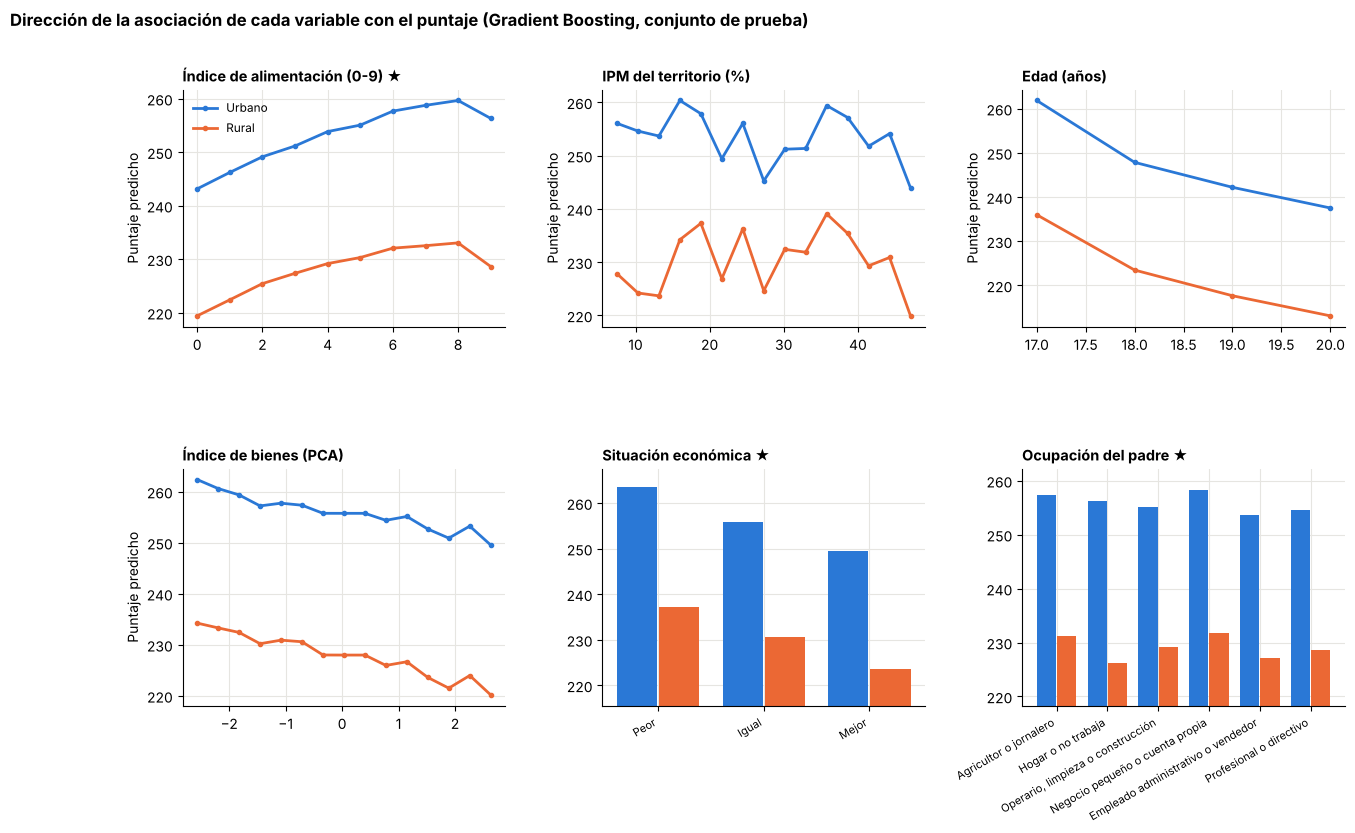

In [ ]:
fig, ejes = plt.subplots(2, 3, figsize=(15, 8), gridspec_kw={"hspace": 0.6, "wspace": 0.3})
ejes = ejes.ravel()
for eje, (variable, titulo) in zip(ejes, paneles_numericos):
    for zona in ["URBANO", "RURAL"]:
        datos = dependencias[(dependencias["variable"] == variable) & (dependencias["zona"] == zona)]
        eje.plot(datos["valor"].astype(float), datos["prediccion"], color=COLOR[zona], linewidth=2, marker="o",
                 markersize=3, label=zona.capitalize())
    eje.set_title(titulo, fontsize=10.5)
    eje.set_ylabel("Puntaje predicho")
for eje, (variable, titulo, categorias, _) in zip(ejes[4:], paneles_categoricos):
    x = np.arange(len(categorias))
    for desplazamiento, zona in [(-0.2, "URBANO"), (0.2, "RURAL")]:
        datos = dependencias[(dependencias["variable"] == variable) & (dependencias["zona"] == zona)] \
            .set_index("valor").loc[categorias]
        eje.bar(x + desplazamiento, datos["prediccion"], width=0.38, color=COLOR[zona])
    eje.set_xticks(x)
    eje.set_xticklabels(categorias, rotation=30, ha="right", fontsize=8)
    eje.set_ylim(dependencias[dependencias["variable"] == variable]["prediccion"].min() - 8,
                 dependencias[dependencias["variable"] == variable]["prediccion"].max() + 4)
    eje.set_title(titulo, fontsize=10.5)
ejes[0].legend(frameon=False, fontsize=8.5)
fig.suptitle(f"Dirección de la asociación de cada variable con el puntaje ({nombre_no_lineal}, conjunto de prueba)",
             x=0.01, ha="left", fontweight="bold")
guardar_figura("G11_dependencia_parcial.png")

## 20. Escenarios de política (contrafactuales)

¿Cuánto cambiaría el puntaje promedio rural predicho si se modificara una condición, dejando todo lo demás igual? Se aplican cinco escenarios, y su combinación, a los estudiantes rurales de prueba:

1. Todos tienen internet y computador.
2. Los de jornada mañana o tarde pasan a jornada única.
3. El IPM de su territorio es igual al de la zona urbana de su departamento.
4. Todas las madres tienen al menos secundaria completa.
5. Alimentación ★: quienes tienen un índice de alimentación por debajo de la mediana urbana pasan a esa mediana.

Son simulaciones basadas en asociaciones, no efectos causales garantizados. Sirven para comparar la magnitud relativa de cada factor.

**Lectura.**

- **Alimentación ★:** el puntaje predicho sube de forma casi continua con el índice: de 0 a 8 aumenta unos 14 puntos en lo rural y 17 en lo urbano. Las curvas son casi paralelas, así que la alimentación se asocia con el desempeño de forma parecida en las dos zonas (la pequeña caída en 9 corresponde a pocos estudiantes).
- **Situación económica ★:** con todo lo demás constante, quienes reportan una situación **peor** tienen un puntaje predicho unos 7 puntos mayor que quienes la reportan **igual**, y quienes la reportan **mejor**, entre 6 y 7 puntos menor, en las dos zonas. El modelo no lineal confirma la paradoja de la sección 15.
- **Ocupación del padre ★:** las diferencias son pequeñas (menos de 5 puntos) y los hijos de agricultores están entre los de mayor puntaje predicho, lo que coincide con los coeficientes de la regresión.
- **Edad:** es la relación más fuerte: cada año de extraedad entre los 17 y los 20 años se asocia en promedio con una caída de cerca de 8 puntos.
- **Índice de bienes:** la curva baja levemente (unos 12 puntos de un extremo al otro), igual que el coeficiente negativo de la regresión: con el estrato, los libros, la conectividad y la educación de los padres en el modelo, el índice capta la parte de los bienes que no se traduce en capital educativo. No debe leerse por separado del resto del grupo socioeconómico.
- **IPM:** la curva es irregular. El IPM tiene solo 66 valores (uno por departamento y zona), así que el modelo de árboles lo usa como un identificador del territorio más que como una escala continua, como se discutió en la sección 17.

In [ ]:
test_rural = test[test["rural"] == 1].reset_index(drop=True)
ipm_urbano_departamento = test[test["rural"] == 0].groupby("cod_depto")["ipm_zona"].first()
brecha_prueba = y_test[test["rural"] == 0].mean() - y_test[test["rural"] == 1].mean()


def escenario_conectividad(X):
    """Todos los estudiantes con internet y computador."""
    X = X.copy()
    for variable in ["internet", "computador"]:
        for columna in [c for c in X.columns if c.startswith(f"{variable}=")]:
            X[columna] = 0.0
        X[f"{variable}=Sí"] = 1.0
    return X


def escenario_jornada_unica(X):
    """Los estudiantes de jornada mañana (referencia) o tarde pasan a jornada única."""
    X = X.copy()
    columnas_jornada = [c for c in X.columns if c.startswith("jornada=")]
    manana_o_tarde = (X["jornada=Tarde"] == 1) | (X[columnas_jornada].sum(axis=1) == 0)
    X.loc[manana_o_tarde, "jornada=Tarde"] = 0.0
    X.loc[manana_o_tarde, "jornada=Única"] = 1.0
    return X


def escenario_ipm_urbano(X):
    """El IPM del territorio rural se reemplaza por el IPM urbano del mismo departamento."""
    X = X.copy()
    X["ipm_zona"] = test_rural["cod_depto"].map(ipm_urbano_departamento).fillna(X["ipm_zona"]).values
    return X


def escenario_madre_secundaria(X):
    """Las madres con primaria o menos, o secundaria incompleta, pasan a secundaria completa."""
    X = X.copy()
    columnas_madre = [c for c in X.columns if c.startswith("educ_madre=")]
    cambiar = (X[columnas_madre].sum(axis=1) == 0) | (X["educ_madre=Secundaria incompleta"] == 1)
    X.loc[cambiar, "educ_madre=Secundaria incompleta"] = 0.0
    X.loc[cambiar, "educ_madre=Secundaria completa"] = 1.0
    return X


mediana_alimentacion_urbana = train.loc[train["rural"] == 0, "indice_alimentacion"].median()


def escenario_alimentacion(X):
    """El índice de alimentación de quienes están por debajo de la mediana urbana sube hasta esa mediana."""
    X = X.copy()
    X["indice_alimentacion"] = X["indice_alimentacion"].clip(lower=mediana_alimentacion_urbana)
    return X


def escenario_combinado(X):
    """Los cinco escenarios al mismo tiempo."""
    return escenario_alimentacion(escenario_madre_secundaria(escenario_ipm_urbano(
        escenario_jornada_unica(escenario_conectividad(X)))))

In [ ]:
escenarios = {
    "Internet y computador para todos los rurales": escenario_conectividad,
    "Jornada única para rurales en jornada mañana/tarde": escenario_jornada_unica,
    "IPM territorial rural igual al urbano del departamento": escenario_ipm_urbano,
    "Madre con al menos secundaria completa": escenario_madre_secundaria,
    "Alimentación al menos en la mediana urbana": escenario_alimentacion,
    "Los cinco escenarios combinados": escenario_combinado,
}

filas = []
for nombre, funcion in escenarios.items():
    X_escenario = funcion(X_test_rural)
    for nombre_modelo, modelo in [(nombre_no_lineal, modelo_no_lineal), ("Regresión lineal", modelo_lineal)]:
        cambio = modelo.predict(X_escenario).mean() - modelo.predict(X_test_rural).mean()
        filas.append({"escenario": nombre, "modelo": nombre_modelo, "cambio_puntaje_rural": cambio,
                      "pct_brecha_cerrada": cambio / brecha_prueba * 100})

tabla_escenarios = pd.DataFrame(filas)
guardar_tabla(tabla_escenarios, "03_escenarios_contrafactuales.csv")
print(f"Brecha observada en prueba: {brecha_prueba:.1f} puntos")
tabla_escenarios.pivot(index="escenario", columns="modelo", values=["cambio_puntaje_rural", "pct_brecha_cerrada"])

Brecha observada en prueba: 27.6 puntos


cambio_puntaje_rural                  pct_brecha_cerrada                 
modelo                                                Gradient Boosting Regresión lineal  Gradient Boosting Regresión lineal
escenario                                                                                                                   
Alimentación al menos en la mediana urbana                        1.226            1.506              4.447            5.463
IPM territorial rural igual al urbano del depar...               -0.477            8.310             -1.728           30.134
Internet y computador para todos los rurales                      4.433            6.383             16.077           23.147
Jornada única para rurales en jornada mañana/tarde                0.813            1.019              2.948            3.695
Los cinco escenarios combinados                                   7.027           18.114             25.483           65.683
Madre con al menos secundaria completa                            0.964            0.895              3.495            3.245

## **Lectura de los escenarios**

Se analizan diferentes escenarios hipotéticos para estimar cuánto podría reducirse la brecha rural-urbana en el puntaje global de Saber 11 si se mejoraran determinadas condiciones de los estudiantes rurales. Para ello, se comparan los resultados de la regresión lineal y Gradient Boosting.

### **Resultados de los escenarios**

**1. Internet y computador para todos**

- Regresión lineal: aumento de **6,4 puntos**, equivalente al **23 % de la brecha**.
- Gradient Boosting: aumento de **4,4 puntos**, equivalente al **16 % de la brecha**.

**2. IPM rural igual al urbano**

- Regresión lineal: aumento de **8,3 puntos**, equivalente al **30 % de la brecha**.
- Gradient Boosting: disminución de **0,5 puntos**. Este resultado requiere una aclaración metodológica que se presenta más adelante.

**3. Alimentación en la mediana urbana ★**

- Regresión lineal: aumento de **1,5 puntos**, equivalente al **5 % de la brecha**.
- Gradient Boosting: aumento de **1,2 puntos**, equivalente al **4 % de la brecha**.

**4. Jornada única**

- Regresión lineal: aumento de **1,0 punto**, equivalente al **4 % de la brecha**.
- Gradient Boosting: aumento de **0,8 puntos**, equivalente al **3 % de la brecha**.

**5. Madre con secundaria completa**

- Regresión lineal: aumento de **0,9 puntos**, equivalente al **3 % de la brecha**.
- Gradient Boosting: aumento de **1,0 punto**, equivalente al **3 % de la brecha**.

**6. Los cinco escenarios combinados**

- Regresión lineal: aumento de **18,1 puntos**, equivalente al **66 % de la brecha**.
- Gradient Boosting: aumento de **7,0 puntos**, equivalente al **25 % de la brecha**.

### **Interpretación de los resultados**

- **La conectividad es la palanca más robusta:** los dos modelos coinciden en que garantizar internet y computador permitiría reducir entre el **16 % y el 23 % de la brecha**. Por esta razón, es una de las intervenciones más relevantes desde la política educativa.

- **Alimentación:** llevar a los estudiantes rurales al menos al nivel de alimentación mediano de las zonas urbanas se asocia con un aumento de entre **1,2 y 1,5 puntos**. Este efecto es comparable al de la jornada única y respalda la importancia de fortalecer el Programa de Alimentación Escolar en las sedes rurales.

- **Nota sobre el IPM en Gradient Boosting:** este escenario asigna a los estudiantes rurales los niveles de IPM de las zonas urbanas. Sin embargo, esta combinación no existe en los datos de entrenamiento, ya que ningún contexto rural presenta un IPM tan bajo. Los modelos basados en árboles no extrapolan fuera de los datos que observaron durante su entrenamiento, por lo que su predicción prácticamente no cambia.

  En este escenario, la referencia más adecuada es el modelo lineal. Por su parte, el efecto combinado de Gradient Boosting debe interpretarse como un límite inferior.

## 21. Focalización: ¿dónde intervenir primero?

Para priorizar territorios se necesita una probabilidad de bajo desempeño para todos los estudiantes, calculada sin que el modelo haya visto su sede. Se obtiene con `cross_val_predict` (validación cruzada de 5 pliegues agrupada por sede): la probabilidad de cada estudiante la calcula un modelo entrenado sin su colegio.

In [ ]:
yb_completa = (y_completa < umbral_bajo).astype(int)
probabilidad_oof = cross_val_predict(HistGradientBoostingClassifier(**hgb_base, **mejor_hgb), X_completa, yb_completa,
                                     groups=completa["sede"].values, cv=GroupKFold(5), method="predict_proba")[:, 1]
print(f"ROC-AUC fuera de muestra (todos los estudiantes): {roc_auc_score(yb_completa, probabilidad_oof):.3f}")

riesgo = completa[["departamento", "municipio", "cod_mcpio", "zona"]].copy()
riesgo["bajo_desempeno"] = yb_completa
riesgo["probabilidad"] = probabilidad_oof

riesgo_departamento = riesgo.groupby(["departamento", "zona"]).agg(
    estudiantes=("probabilidad", "size"),
    pct_bajo_observado=("bajo_desempeno", "mean"),
    probabilidad_media=("probabilidad", "mean"),
    riesgo_alto=("probabilidad", lambda p: (p >= 0.7).sum())).reset_index()
riesgo_departamento[["pct_bajo_observado", "probabilidad_media"]] *= 100
guardar_tabla(riesgo_departamento, "03_riesgo_por_departamento.csv")

riesgo_municipio = riesgo[riesgo["zona"] == "RURAL"].groupby(["departamento", "municipio"]).agg(
    estudiantes=("probabilidad", "size"), pct_bajo_observado=("bajo_desempeno", "mean"),
    probabilidad_media=("probabilidad", "mean")).reset_index()
riesgo_municipio = riesgo_municipio[riesgo_municipio["estudiantes"] >= 100]
riesgo_municipio[["pct_bajo_observado", "probabilidad_media"]] *= 100
riesgo_municipio = riesgo_municipio.sort_values("probabilidad_media", ascending=False)
guardar_tabla(riesgo_municipio.head(30), "03_top30_municipios_rurales_riesgo.csv")
riesgo_municipio.head(10)

ROC-AUC fuera de muestra (todos los estudiantes): 0.815


,departamento,municipio,estudiantes,pct_bajo_observado,probabilidad_media
577,La Guajira,Uribia,376,86.170,95.289
574,La Guajira,Manaure,314,85.987,93.608
573,La Guajira,Maicao,213,72.770,90.014
928,Vichada,Cumaribo,103,76.699,89.929
161,Bolívar,María La Baja,233,81.974,87.671
567,La Guajira,Albania,100,73.000,87.213
576,La Guajira,San Juan Del Cesar,134,77.612,86.332
575,La Guajira,Riohacha,276,72.464,85.888
833,Sucre,San Onofre,242,69.008,85.697
325,Cauca,Jambaló,123,77.236,85.491


**Gráfica 12. Bajo desempeño rural y urbano por departamento.** Para cada departamento compara el porcentaje de estudiantes con bajo desempeño en la zona rural (naranja) y en la urbana (azul). El número a la derecha es la cantidad de estudiantes rurales con probabilidad predicha de 0,7 o más: el tamaño de la población a focalizar.

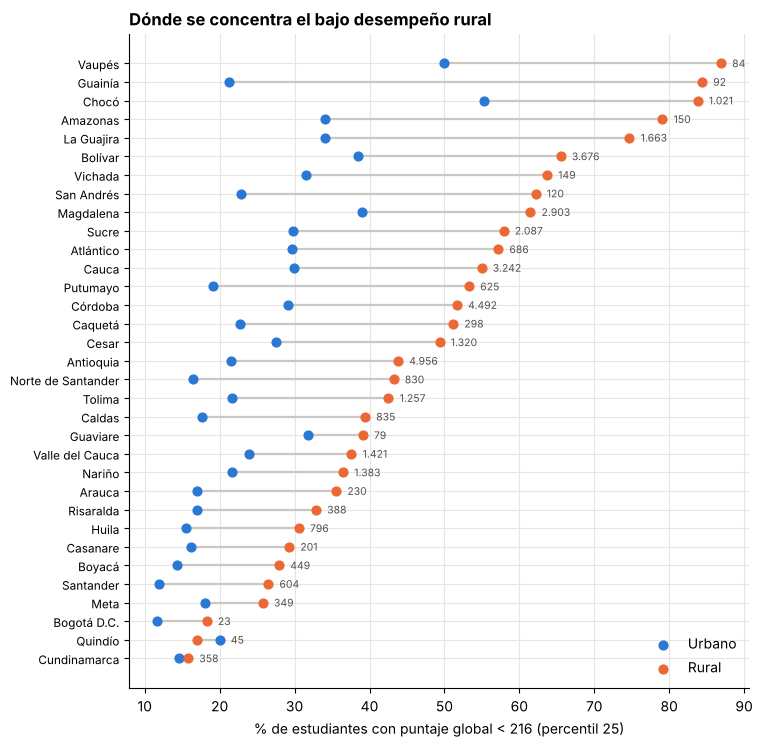

In [ ]:
rural_dep = riesgo_departamento[riesgo_departamento["zona"] == "RURAL"].sort_values("pct_bajo_observado")
urbano_dep = riesgo_departamento[riesgo_departamento["zona"] == "URBANO"].set_index("departamento") \
    .loc[rural_dep["departamento"]]

plt.figure(figsize=(8, 8.5))
y = np.arange(len(rural_dep))
plt.hlines(y, urbano_dep["pct_bajo_observado"], rural_dep["pct_bajo_observado"], color="#c9c8c3", linewidth=1.6)
plt.scatter(urbano_dep["pct_bajo_observado"], y, color=COLOR["URBANO"], s=40, zorder=3, label="Urbano")
plt.scatter(rural_dep["pct_bajo_observado"], y, color=COLOR["RURAL"], s=40, zorder=3, label="Rural")
for i, (_, fila) in enumerate(rural_dep.iterrows()):
    maximo = max(fila["pct_bajo_observado"], urbano_dep.loc[fila["departamento"], "pct_bajo_observado"])
    plt.text(maximo + 1.5, i, f"{fila['riesgo_alto']:,}".replace(",", "."), va="center", fontsize=7.5, color="#52514e")
plt.yticks(y, rural_dep["departamento"], fontsize=8.5)
plt.xlabel(f"% de estudiantes con puntaje global < {umbral_bajo:.0f} (percentil 25)")
plt.title("Dónde se concentra el bajo desempeño rural")
plt.legend(loc="lower right", frameon=False)
guardar_figura("G12_riesgo_por_departamento.png")

**Lectura.** Hay dos criterios para priorizar, y conviene usar los dos:

- **Por tasa:** los departamentos con mayor proporción de bajo desempeño rural son Vaupés, Guainía, Chocó, Amazonas y La Guajira, con entre 75 % y 87 % de sus estudiantes rurales por debajo del percentil 25.
- **Por volumen:** los que concentran más estudiantes rurales en riesgo alto son Antioquia (unos 5.000), Córdoba, Bolívar, Cauca y Magdalena.
- **Municipios:** la tabla de municipios rurales con más riesgo la encabezan Uribia, Manaure y Maicao, en La Guajira, seguidos de Cumaribo (Vichada) y María La Baja (Bolívar). Coinciden con el tipo 1 de sede rural de la parte F.

---
# PARTE F. Tipología de sedes rurales oficiales (K-means)

## **22. ¿Hay distintos tipos de colegio rural?**

Las partes anteriores tratan a los estudiantes rurales como un solo grupo. Pero una sede rural de La Guajira y una del Eje Cafetero pueden enfrentar problemas muy distintos. Para encontrar perfiles de sede* se usa K-means, un método no supervisado: agrupa sedes parecidas sin mirar el puntaje. El puntaje se usa solo al final, para describir los grupos.

- **Unidad:** sedes rurales oficiales con al menos 10 estudiantes (el 94 % de los rurales estudia en colegios oficiales; las no oficiales forman un grupo aparte, muy distinto, que dominaría la agrupación).
- **Variables (12):** promedio por sede de conectividad, educación de la madre, ocupación del padre, focalización por Sisbén, alimentación, trabajo, extraedad, movilidad, IPM del territorio, NSE del colegio y jornada única o completa.
- **Escalado:** las variables se estandarizan antes de K-means, porque el algoritmo usa distancias y, sin escalar, el IPM (en puntos porcentuales) dominaría a las proporciones (entre 0 y 1).
- **Número de grupos:** se prueba $k$ entre 2 y 8 y se usa el coeficiente de silueta(qué tan cerca está cada sede de su grupo frente al grupo más cercano) junto con la inercia (método del codo).

In [ ]:
rurales_oficiales = completa[(completa["rural"] == 1) & (completa["naturaleza"] == "Oficial")]
indicadores_sede = rurales_oficiales.assign(
    internet_si=rurales_oficiales["internet"].eq("Sí"), computador_si=rurales_oficiales["computador"].eq("Sí"),
    madre_primaria=rurales_oficiales["educ_madre"].eq("Primaria o menos"),
    padre_agricultor=rurales_oficiales["ocup_padre"].eq("Agricultor o jornalero"),
    etnia_si=rurales_oficiales["etnia"].eq("Sí"),
    jornada_extendida=rurales_oficiales["jornada"].isin(["Única", "Completa"]),
    nse_numero=rurales_oficiales["nse_colegio"].str[-1].astype(int))
sedes_rurales = indicadores_sede.groupby("sede").agg(
    departamento=("departamento", "first"), municipio=("municipio", "first"),
    estudiantes=("punt_global", "size"), puntaje_medio=("punt_global", "mean"),
    pct_internet=("internet_si", "mean"), pct_computador=("computador_si", "mean"),
    pct_madre_primaria=("madre_primaria", "mean"), pct_padre_agricultor=("padre_agricultor", "mean"),
    pct_focalizado_sisben=("focalizado_sisben", "mean"), indice_alimentacion=("indice_alimentacion", "mean"),
    pct_trabaja=("trabaja", "mean"), pct_extraedad=("extraedad", "mean"),
    pct_presenta_otro_mcpio=("presenta_otro_mcpio", "mean"), ipm_zona=("ipm_zona", "mean"),
    nse_colegio=("nse_numero", "mean"), pct_jornada_extendida=("jornada_extendida", "mean"),
    pct_etnia=("etnia_si", "mean"))
sedes_rurales = sedes_rurales[sedes_rurales["estudiantes"] >= 10].copy()
variables_cluster = ["pct_internet", "pct_computador", "pct_madre_primaria", "pct_padre_agricultor",
                     "pct_focalizado_sisben", "indice_alimentacion", "pct_trabaja", "pct_extraedad",
                     "pct_presenta_otro_mcpio", "ipm_zona", "nse_colegio", "pct_jornada_extendida"]
print(f"Sedes rurales oficiales con al menos 10 estudiantes: {len(sedes_rurales):,} "
      f"({sedes_rurales['estudiantes'].sum():,} estudiantes)")

escalador_cluster = StandardScaler()
Z_sedes = escalador_cluster.fit_transform(sedes_rurales[variables_cluster].fillna(sedes_rurales[variables_cluster].median()))

filas = []
for k in range(2, 9):
    kmeans = KMeans(n_clusters=k, n_init=20, random_state=SEMILLA).fit(Z_sedes)
    filas.append({"k": k, "inercia": kmeans.inertia_, "silueta": silhouette_score(Z_sedes, kmeans.labels_),
                  "sedes_grupo_mas_pequeno": np.bincount(kmeans.labels_).min()})
seleccion_k = pd.DataFrame(filas)
guardar_tabla(seleccion_k, "03_kmeans_seleccion_k.csv")
seleccion_k

Sedes rurales oficiales con al menos 10 estudiantes: 2,620 (66,656 estudiantes)


,k,inercia,silueta,sedes_grupo_mas_pequeno
0,2,"25,013.699",0.194,849
1,3,"22,222.015",0.155,713
2,4,"20,226.723",0.149,418
3,5,"18,526.606",0.160,119
4,6,"17,591.326",0.142,108
5,7,"16,841.153",0.139,106
6,8,"16,218.308",0.137,107


La silueta es baja para todos los valores de $k$ (menos de 0,2): las sedes rurales oficiales forman un **continuo** más que grupos bien separados, algo esperable en datos sociales. Con $k = 2$ la silueta es la mayor (0,19), pero solo separa a las sedes con mejores condiciones del resto, lo que no ayuda a diferenciar políticas. Entre $k = 3$ y $k = 8$, la silueta más alta es la de **$k = 5$** (0,16) y el grupo más pequeño tiene 119 sedes, un tamaño suficiente para describirlo. La inercia no muestra un codo marcado. Se eligen 5 tipos, con la advertencia de que las fronteras entre ellos son graduales.

In [ ]:
K_ELEGIDO = int(seleccion_k[seleccion_k["k"] >= 3].sort_values("silueta", ascending=False)["k"].iloc[0])
kmeans = KMeans(n_clusters=K_ELEGIDO, n_init=20, random_state=SEMILLA).fit(Z_sedes)

# Se numeran los grupos de menor a mayor puntaje medio para que la lectura sea ordenada
orden = sedes_rurales.groupby(kmeans.labels_)["puntaje_medio"].mean().sort_values().index
sedes_rurales["tipo"] = pd.Series(kmeans.labels_, index=sedes_rurales.index).map(
    {grupo: i + 1 for i, grupo in enumerate(orden)})

perfil_tipos = sedes_rurales.groupby("tipo").agg(
    sedes=("estudiantes", "size"), estudiantes=("estudiantes", "sum"),
    puntaje_medio=("puntaje_medio", "mean"), **{v: (v, "mean") for v in variables_cluster},
    pct_etnia=("pct_etnia", "mean")).T   # la etnia no se usa para agrupar; solo describe los tipos
guardar_tabla(perfil_tipos, "03_kmeans_perfil_tipos_sede.csv", index=True)
guardar_tabla(sedes_rurales.reset_index(), "03_kmeans_sedes_rurales_tipo.csv")
print(f"k elegido = {K_ELEGIDO}")
perfil_tipos

k elegido = 5


tipo,1,2,3,4,5
sedes,119.000,712.000,762.000,633.000,394.000
estudiantes,"2,676.000","19,932.000","15,985.000","14,028.000","14,035.000"
puntaje_medio,190.776,215.640,219.676,232.046,245.237
pct_internet,0.240,0.239,0.148,0.386,0.679
pct_computador,0.282,0.222,0.153,0.360,0.589
pct_madre_primaria,0.580,0.423,0.655,0.528,0.304
pct_padre_agricultor,0.251,0.336,0.543,0.505,0.204
pct_focalizado_sisben,0.294,0.874,0.848,0.716,0.497
indice_alimentacion,3.639,4.170,3.943,4.880,5.230
pct_trabaja,0.768,0.479,0.648,0.648,0.417


In [ ]:
# Departamentos donde más pesa cada tipo (por número de estudiantes)
tipo_departamento = sedes_rurales.groupby(["tipo", "departamento"])["estudiantes"].sum().reset_index() \
    .sort_values(["tipo", "estudiantes"], ascending=[True, False]).groupby("tipo").head(4)
tipo_departamento.groupby("tipo")["departamento"].apply(", ".join).rename("departamentos con más estudiantes")

tipo
1                 La Guajira, Cauca, Chocó, Vichada
2                Córdoba, Bolívar, Magdalena, Cesar
3                 Córdoba, Antioquia, Nariño, Cauca
4         Huila, Antioquia, Santander, Cundinamarca
5    Cundinamarca, Antioquia, Valle del Cauca, Meta
Name: departamentos con más estudiantes, dtype: str

**Gráfica 13. Tipología de sedes rurales oficiales.** A la izquierda, las sedes proyectadas en los dos primeros componentes principales de las 12 variables estandarizadas (el PCA solo se usa para dibujar; los grupos se forman con las 12 variables). A la derecha, el perfil de cada tipo: cuántas desviaciones estándar se aleja del promedio de las sedes rurales oficiales en cada variable (rojo = más alto, azul = más bajo).

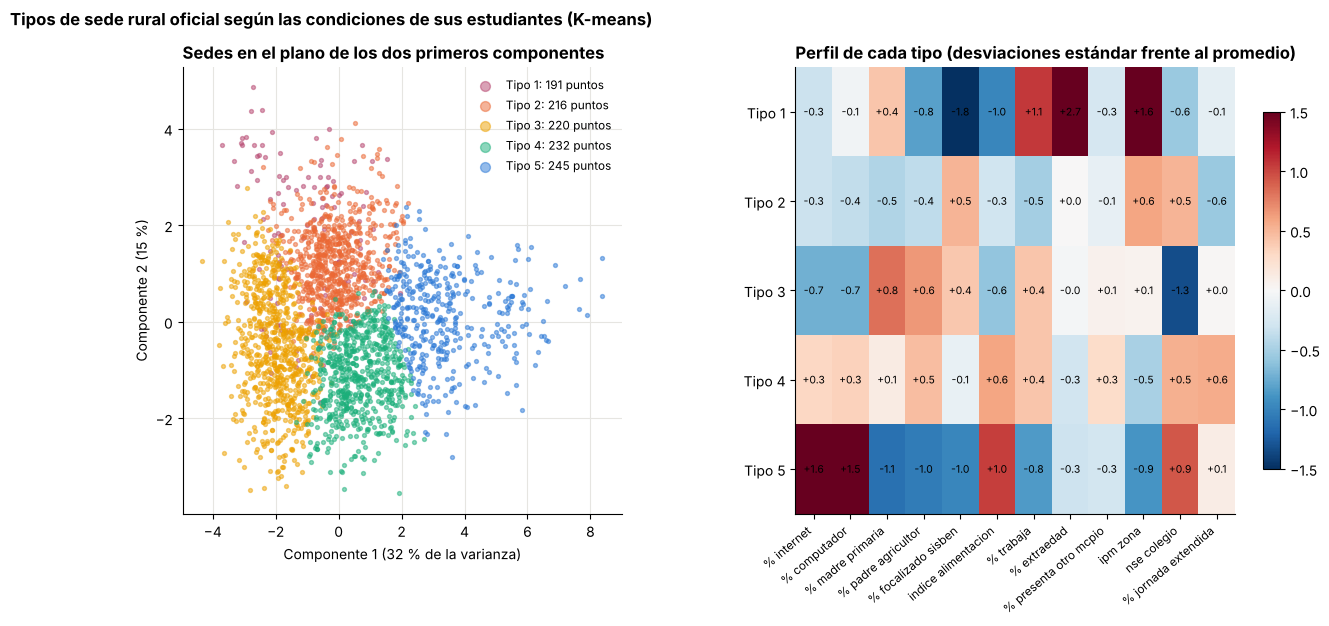

In [ ]:
pca_sedes = PCA(n_components=2, random_state=SEMILLA).fit(Z_sedes)
coordenadas = pca_sedes.transform(Z_sedes)
colores_tipo = ["#b5446e", "#eb6834", "#eda100", "#1baf7a", "#2a78d6", "#4a3aa7", "#8a8984", "#0b0b0b"]

fig, ejes = plt.subplots(1, 2, figsize=(15, 5.8), gridspec_kw={"width_ratios": [1, 1.25], "wspace": 0.35})
for tipo in sorted(sedes_rurales["tipo"].unique()):
    es_tipo = sedes_rurales["tipo"].values == tipo
    ejes[0].scatter(coordenadas[es_tipo, 0], coordenadas[es_tipo, 1], s=8, alpha=0.5, color=colores_tipo[tipo - 1],
                    label=f"Tipo {tipo}: {sedes_rurales.loc[es_tipo, 'puntaje_medio'].mean():.0f} puntos")
ejes[0].set_xlabel(f"Componente 1 ({pca_sedes.explained_variance_ratio_[0] * 100:.0f} % de la varianza)")
ejes[0].set_ylabel(f"Componente 2 ({pca_sedes.explained_variance_ratio_[1] * 100:.0f} %)")
ejes[0].set_title("Sedes en el plano de los dos primeros componentes")
ejes[0].legend(frameon=False, fontsize=8.5, markerscale=2.5)

perfil_z = pd.DataFrame(Z_sedes, columns=variables_cluster, index=sedes_rurales.index) \
    .groupby(sedes_rurales["tipo"]).mean()
imagen = ejes[1].imshow(perfil_z.values, cmap="RdBu_r", vmin=-1.5, vmax=1.5, aspect="auto")
ejes[1].set_yticks(range(len(perfil_z)), [f"Tipo {t}" for t in perfil_z.index])
ejes[1].set_xticks(range(len(variables_cluster)), [v.replace("pct_", "% ").replace("_", " ") for v in variables_cluster],
                   rotation=40, ha="right", fontsize=8.5)
for i in range(perfil_z.shape[0]):
    for j in range(perfil_z.shape[1]):
        ejes[1].text(j, i, f"{perfil_z.values[i, j]:+.1f}", ha="center", va="center", fontsize=7.5)
ejes[1].grid(False)
ejes[1].set_title("Perfil de cada tipo (desviaciones estándar frente al promedio)")
fig.colorbar(imagen, ax=ejes[1], shrink=0.8)
fig.suptitle("Tipos de sede rural oficial según las condiciones de sus estudiantes (K-means)", x=0.01, ha="left",
             fontweight="bold")
guardar_figura("G13_tipologia_sedes_rurales.png")

## **tipología de las sedes rurales oficiales**

Los cinco tipos identificados permiten ordenar las sedes rurales oficiales de menor a mayor puntaje medio. Entre el primer y el último tipo existe una diferencia de 54 puntos, una distancia casi dos veces mayor que la brecha rural-urbana.

### **Caracterización de los cinco tipos de sedes**

**1. Tipo 1. Pobreza extrema y rezago**

- **Número de sedes:** 119.
- **Puntaje medio:** 191 puntos.
- **Perfil:** presenta un IPM del 55 %, un 48 % de estudiantes con extraedad, un 77 % que trabaja y las peores condiciones de alimentación.
- **Ubicación principal:** La Guajira, Cauca, Chocó y Vichada.
- **Prioridad sugerida:** fortalecer la permanencia escolar, la alimentación y los programas de nivelación por edad.

**2. Tipo 2. Rural pobre con jornada corta**

- **Número de sedes:** 712.
- **Puntaje medio:** 216 puntos.
- **Perfil:** presenta un IPM del 43 % y solamente el 18 % de los estudiantes pertenece a sedes con jornada única o completa. Además, el 24 % cuenta con internet.
- **Ubicación principal:** Córdoba, Bolívar, Magdalena y Cesar.
- **Prioridad sugerida:** ampliar la jornada escolar y mejorar la conectividad.

**3. Tipo 3. Campesina aislada**

- **Número de sedes:** 762.
- **Puntaje medio:** 220 puntos.
- **Perfil:** el 54 % de los padres son agricultores, el 66 % de las madres tiene educación primaria, solamente el 15 % cuenta con internet y predominan los colegios de NSE 1.
- **Ubicación principal:** Córdoba, Antioquia, Nariño y Cauca.
- **Prioridad sugerida:** mejorar la conectividad y fortalecer el apoyo a los colegios de nivel socioeconómico bajo.

**4. Tipo 4. Campesina con jornada extendida**

- **Número de sedes:** 633.
- **Puntaje medio:** 232 puntos.
- **Perfil:** el 73 % pertenece a sedes con jornada única o completa y el 52 % de los estudiantes presenta el examen en otro municipio.
- **Ubicación principal:** Huila, Antioquia, Santander y Cundinamarca.
- **Prioridad sugerida:** mejorar las condiciones de transporte y facilitar el acceso a las instituciones educativas.

**5. Tipo 5. Rural conectada**

- **Número de sedes:** 394.
- **Puntaje medio:** 245 puntos.
- **Perfil:** el 68 % cuenta con internet y presenta un IPM del 27 %.
- **Ubicación principal:** Cundinamarca, Antioquia, Valle y Meta.
- **Prioridad sugerida:** tiene una menor prioridad de intervención, debido a que presenta mejores condiciones relativas frente a los demás grupos.

###**Hallazgo 3. Las sedes más pobres son las menos focalizadas por el Sisbén**

En el tipo 1, que presenta los mayores niveles de pobreza y el menor puntaje académico, solamente el 29 % de los estudiantes está focalizado por el Sisbén para Generación E. Esta proporción contrasta con el 87 % del tipo 2 y el 50 % del tipo 5, que presenta las mejores condiciones.

Este resultado sugiere la posible existencia de un error de exclusión en la focalización, es decir, que algunos de los estudiantes más vulnerables podrían estar quedando por fuera de los programas de apoyo.

Una posible explicación está relacionada con las características étnicas de la población. En el tipo 1, en promedio, el 88 % de los estudiantes de cada sede pertenece a un grupo étnico. Esta variable no se utilizó para construir los grupos. En los resguardos indígenas, parte de la población suele registrarse mediante censos propios y no necesariamente aparece en el Sisbén.

Se trata de una hipótesis que debe verificarse mediante los registros administrativos. Sin embargo, plantea una advertencia importante: utilizar únicamente el Sisbén como mecanismo de focalización podría dejar por fuera a los estudiantes rurales más vulnerables.

### **Comparación entre los tipos 2 y 3**

Los tipos 2 y 3 presentan niveles de pobreza similares, pero el tipo 3 obtiene un puntaje promedio ligeramente superior, con 220 puntos frente a 216 puntos del tipo 2.

Esto resulta interesante porque el tipo 3 tiene menor conectividad, pero presenta una mayor proporción de jornada extendida: 46 % frente al 18 % del tipo 2.

Este resultado es coherente con la asociación positiva de la jornada única encontrada en la sección 15 y sugiere que la ampliación de la jornada escolar podría estar relacionada con mejores resultados académicos, incluso en contextos rurales con limitaciones de conectividad.

---
# **Conclusiones**

1. **Magnitud.** La brecha rural-urbana en Saber 11 2020-2 es de 28 puntos, pero **no es un efecto de la ruralidad en sí**: con características comparables, los estudiantes rurales obtienen igual o algo más que los urbanos (+3,9 puntos).
2. **Causas asociadas.** La brecha se explica por **desventajas acumuladas**: el contexto territorial, la composición socioeconómica de los colegios (≈ 25-28 %), la conectividad del hogar (≈ 17-19 %), la alimentación y la situación económica del hogar (≈ 8 %), y la edad, el trabajo y la educación de los padres. Oaxaca-Blinder (modelo lineal) y Shapley (Gradient Boosting) coinciden en estos aportes; difieren solo en cómo reparten el aporte territorial entre la zona y el IPM.
3. **Aporte de la revisión de variables.** Las 13 variables incorporadas aumentan la varianza explicada en 3,7 puntos porcentuales (de 0,397 a 0,434 en el mejor modelo) y el PR-AUC de la clasificación de 0,590 a 0,616. Las que más aportan son la lectura por gusto, la situación económica, la alimentación, el uso de internet y la ocupación de los padres.
4. **Hallazgos nuevos.**
   - **Situación económica:** quienes reportan que su hogar empeoró frente al año anterior obtienen unos 8 puntos más, aun con todos los controles. La pregunta parece medir la exposición al choque de la pandemia y no la pobreza.
   - **Ocupación agrícola:** a igualdad de educación e ingresos, los hijos de agricultores no tienen desventaja; su rezago bruto se debe a las demás condiciones del hogar.
   - **Alimentación:** es un canal propio de la brecha (cerca de 1,2 puntos) y no estaba en el análisis anterior.
   - **Focalización:** en las sedes rurales más pobres (tipo 1 de la parte F) solo el 29 % de los estudiantes está focalizado por el Sisbén, lo que sugiere un posible error de exclusión.
5. **Política.** Los resultados sugieren priorizar la conectividad rural(la palanca más robusta), fortalecer los colegios oficiales rurales de NSE bajo y la alimentación escolar, y atender la extraedad y el trabajo de los estudiantes. La tipología de la parte F permite diferenciar la intervención por tipo de sede, y las probabilidades del clasificador identifican los departamentos y municipios con mayor riesgo.
